<style>
.jp-RenderedHTMLCommon h1 {
  color:#0B1F33; border-bottom:2px solid #DCE7F2; padding-bottom:8px;
  margin-top:1.45em; font-weight:750; letter-spacing:-0.02em;
}
.jp-RenderedHTMLCommon h2 { color:#123B5D; font-weight:700; margin-top:1.25em; }
.jp-RenderedHTMLCommon h3 { color:#2563EB; font-weight:700; }
.jp-RenderedHTMLCommon p, .jp-RenderedHTMLCommon li { line-height:1.72; }
.jp-RenderedHTMLCommon blockquote {
  border-left:4px solid #06B6D4; background:#F0F9FC; color:#334E68;
  padding:10px 16px; border-radius:0 8px 8px 0;
}
</style>

<div style="text-align:center; padding:42px 28px; border-radius:20px;
            background:linear-gradient(135deg,#071827 0%,#123B5D 56%,#2563EB 100%);
            box-shadow:0 12px 32px rgba(11,31,51,.20); color:white;">

  <div style="font-size:12px; letter-spacing:2.2px; font-weight:700; color:#BFEFFF; margin:4px 0 14px;">
    PERSAMAAN DIFERENSIAL PARSIAL · TELEGRAPHER EQUATIONS · FDTD
  </div>
  <h1 style="color:white; border:0; margin:0; font-size:34px; line-height:1.18;">
    Simulasi Tegangan dan Arus Listrik<br>pada Saluran Transmisi
  </h1>
  <p style="max-width:760px; margin:18px auto 24px; color:#E5F3FA; font-size:16px; line-height:1.65;">
    Dari hukum Kirchhoff dan formulasi PDE hingga skema numerik, validasi,
    neraca energi, studi parameter, visualisasi 3D, dan animasi konseptual.
  </p>
  <div style="display:inline-block; min-width:460px; padding:15px 24px; border-radius:12px;
              background:rgba(255,255,255,.11); border:1px solid rgba(255,255,255,.22);">
    <b style="font-size:17px;">Riga Aryadi Pratama</b> &nbsp;·&nbsp; 5002211172<br>
    <span style="color:#D8EAF6; line-height:1.7;">
      Institut Teknologi Sepuluh Nopember 
    </span>
  </div>
</div>



# Ringkasan Eksekutif

Dalam notebook ini saya memodelkan dinamika **tegangan** $V(x,t)$ dan **arus** $I(x,t)$ pada saluran transmisi dengan Persamaan Telegraf. Saya memulai dari rangkaian elementer terdistribusi $R'L'G'C'$, menurunkan sistem PDE dengan hukum Kirchhoff, lalu menyelesaikannya menggunakan **Finite-Difference Time-Domain (FDTD)** pada grid berselang-seling.

Analisis saya mencakup:

1. derivasi Persamaan Telegraf orde satu dan orde dua;
2. interpretasi kecepatan rambat, impedansi karakteristik, redaman, dan distorsi;
3. penurunan skema FDTD beserta syarat stabilitas Courant–Friedrichs–Lewy;
4. simulasi pulsa tegangan yang membelah, merambat, dan memantul;
5. visualisasi profil, heatmap ruang–waktu, serta permukaan 3D;
6. **animasi interaktif konseptual** tegangan dan arus;
7. verifikasi neraca energi elektromagnetik;
8. validasi terhadap solusi analitik mode tunggal;
9. studi konvergensi grid dan sensitivitas parameter saluran.

**Pertanyaan utama saya:** apakah diskretisasi numerik mampu mereproduksi perambatan, redaman, refleksi, dan konservasi/disipasi energi sesuai teori fisika?

# Tujuan Pembelajaran dan Ruang Lingkup

Setelah menyelesaikan notebook ini, saya dapat:

- menjelaskan asal setiap suku pada Persamaan Telegraf;
- membedakan rugi konduktor $R'$ dan rugi dielektrik $G'$;
- menghubungkan PDE orde satu dengan persamaan gelombang teredam orde dua;
- mengimplementasikan skema leapfrog pada grid Yee satu dimensi;
- memeriksa stabilitas, konsistensi kondisi batas, dan konvergensi numerik;
- menafsirkan tegangan, arus, energi, dan daya rugi secara fisik.

Saya membatasi kajian pada saluran transmisi satu dimensi, linear, homogen, dan parameter per satuan panjang yang konstan. Kedua ujung dibuat **hubung-singkat ideal**, sehingga $V(0,t)=V(\ell,t)=0$ dan pulsa mengalami refleksi.

# Daftar Isi

1. [Persiapan dan Reprodusibilitas](#0-persiapan-dan-reprodusibilitas)
2. [Model Fisik Saluran Transmisi](#1-model-fisik-saluran-transmisi)
3. [Formulasi PDE dan Solusi Modal](#2-formulasi-pde-dan-solusi-modal)
4. [Diskretisasi FDTD](#3-diskretisasi-finite-difference-time-domain)
5. [Konfigurasi dan Eksekusi Simulasi](#4-konfigurasi-dan-eksekusi-simulasi)
6. [Visualisasi dan Animasi](#5-visualisasi-hasil-simulasi)
7. [Neraca Energi](#6-neraca-energi-elektromagnetik)
8. [Validasi dan Konvergensi](#7-validasi-terhadap-solusi-analitik)
9. [Studi Parameter](#9-studi-parameter-fisik)
10. [Dashboard Verifikasi](#10-dashboard-verifikasi-numerik)
11. [Keterbatasan dan Kesimpulan](#11-keterbatasan-dan-pengembangan)

# 0. Persiapan dan Reprodusibilitas

Saya menggunakan satu random seed dan seluruh parameter didefinisikan eksplisit dalam satuan SI. Notebook ini tidak membutuhkan data eksternal. Animasi dirender sebagai HTML mandiri sehingga kontrol **play**, **pause**, dan penggeser frame tetap tersedia saat notebook dibuka.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches

from matplotlib import animation, ticker
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.lines import Line2D
from IPython.display import display, Markdown, HTML

SEED = 42
rng = np.random.default_rng(SEED)

np.set_printoptions(precision=5, suppress=True)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda value: f"{value:,.6g}")

BRAND = {
    "ink": "#0B1F33",
    "navy": "#123B5D",
    "blue": "#2563EB",
    "cyan": "#06B6D4",
    "teal": "#0F9D88",
    "amber": "#F59E0B",
    "coral": "#EF6C63",
    "purple": "#7C3AED",
    "muted": "#6B7C93",
    "soft": "#A9B8C6",
    "grid": "#DCE4EC",
    "paper": "#F7F9FC",
    "white": "#FFFFFF",
    "light_blue": "#EAF2FF",
}
COLORS = [BRAND["blue"], BRAND["cyan"], BRAND["teal"],
          BRAND["amber"], BRAND["coral"], BRAND["purple"]]

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "figure.dpi": 125,
    "figure.facecolor": BRAND["paper"],
    "savefig.facecolor": BRAND["paper"],
    "axes.facecolor": BRAND["white"],
    "axes.edgecolor": BRAND["grid"],
    "axes.labelcolor": BRAND["ink"],
    "axes.labelsize": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.titlecolor": BRAND["ink"],
    "axes.titlepad": 13,
    "xtick.color": BRAND["muted"],
    "ytick.color": BRAND["muted"],
    "grid.color": BRAND["grid"],
    "grid.alpha": 0.62,
    "grid.linewidth": 0.75,
    "legend.frameon": False,
    "legend.fontsize": 9.5,
    "figure.titlesize": 18,
    "figure.titleweight": "bold",
    "animation.embed_limit": 80,
})


def style_axis(ax, grid="y"):
    ax.set_facecolor(BRAND["white"])
    ax.set_axisbelow(True)
    ax.grid(False)
    if grid:
        ax.grid(True, axis=grid, color=BRAND["grid"], linewidth=0.75, alpha=0.68)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(BRAND["grid"])
        ax.spines[side].set_linewidth(0.8)
    ax.tick_params(length=0, pad=6, colors=BRAND["muted"])
    return ax


def figure_header(fig, title, subtitle, title_y=0.985, subtitle_y=0.88):
    fig.suptitle(title, x=0.055, y=title_y, ha="left",
                 color=BRAND["ink"], fontsize=18)
    fig.text(0.055, subtitle_y, subtitle, ha="left",
             color=BRAND["muted"], fontsize=10.5)


def polish_table(df, formatters=None, hide_index=False, gradient_subset=None):
    styler = df.style.format(formatters or {})
    styler = styler.set_table_styles([
        {"selector": "thead th", "props": [
            ("background-color", BRAND["navy"]), ("color", "white"),
            ("font-weight", "700"), ("padding", "9px 12px"),
            ("border", "0"), ("text-align", "left")
        ]},
        {"selector": "tbody td", "props": [
            ("padding", "8px 12px"),
            ("border-bottom", f"1px solid {BRAND['grid']}")
        ]},
        {"selector": "tbody tr:nth-child(even)",
         "props": [("background-color", "#F7F9FC")]},
        {"selector": "tbody tr:hover",
         "props": [("background-color", BRAND["light_blue"])]},
    ]).set_properties(**{"color": BRAND["ink"], "font-size": "10.5pt"})
    if gradient_subset:
        styler = styler.background_gradient(subset=gradient_subset, cmap="Blues")
    if hide_index:
        styler = styler.hide(axis="index")
    return styler


def metric_card(ax, label, value, detail, color):
    ax.set_facecolor(BRAND["white"])
    for spine in ax.spines.values():
        spine.set_color(BRAND["grid"])
        spine.set_linewidth(0.9)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.text(0.07, 0.78, label.upper(), transform=ax.transAxes,
            color=BRAND["muted"], fontsize=9, fontweight="bold", va="top")
    ax.text(0.07, 0.49, value, transform=ax.transAxes,
            color=color, fontsize=23, fontweight="bold", va="center")
    ax.text(0.07, 0.15, detail, transform=ax.transAxes,
            color=BRAND["muted"], fontsize=8.5, va="bottom")
    ax.plot([0.07, 0.30], [0.07, 0.07], transform=ax.transAxes,
            color=color, linewidth=4, solid_capstyle="round")


def trapz(y, x):
    if hasattr(np, "trapezoid"):
        return np.trapezoid(y, x)
    return np.trapz(y, x)


print(f"Python       : {sys.version.split()[0]}")
print(f"NumPy       : {np.__version__}")
print(f"Pandas      : {pd.__version__}")
print(f"Platform    : {platform.system()} {platform.release()}")
print(f"Random seed : {SEED}")
print("Visual theme: Electric Navy / Cyan / Amber — aktif")

Python       : 3.12.14
NumPy       : 2.3.5
Pandas      : 2.2.3
Platform    : Linux 6.18.57
Random seed : 42
Visual theme: Electric Navy / Cyan / Amber — aktif


# 1. Model Fisik Saluran Transmisi

Saluran transmisi tidak dapat selalu dianggap sebagai satu resistor, induktor, atau kapasitor terkonsentrasi. Ketika waktu rambat sinyal sebanding dengan skala waktu perubahan sinyal, parameter listrik harus dipandang **terdistribusi sepanjang posisi** $x$.

Untuk elemen sangat kecil $\Delta x$, saya menggunakan:

| Parameter | Makna fisik | Satuan |
|---|---|---|
| $R'$ | resistansi seri per panjang | $\Omega/\mathrm{m}$ |
| $L'$ | induktansi seri per panjang | $\mathrm{H}/\mathrm{m}$ |
| $G'$ | konduktansi bocor per panjang | $\mathrm{S}/\mathrm{m}$ |
| $C'$ | kapasitansi shunt per panjang | $\mathrm{F}/\mathrm{m}$ |

Tanda prime menegaskan bahwa parameter tersebut adalah **per satuan panjang**, bukan nilai komponen total.

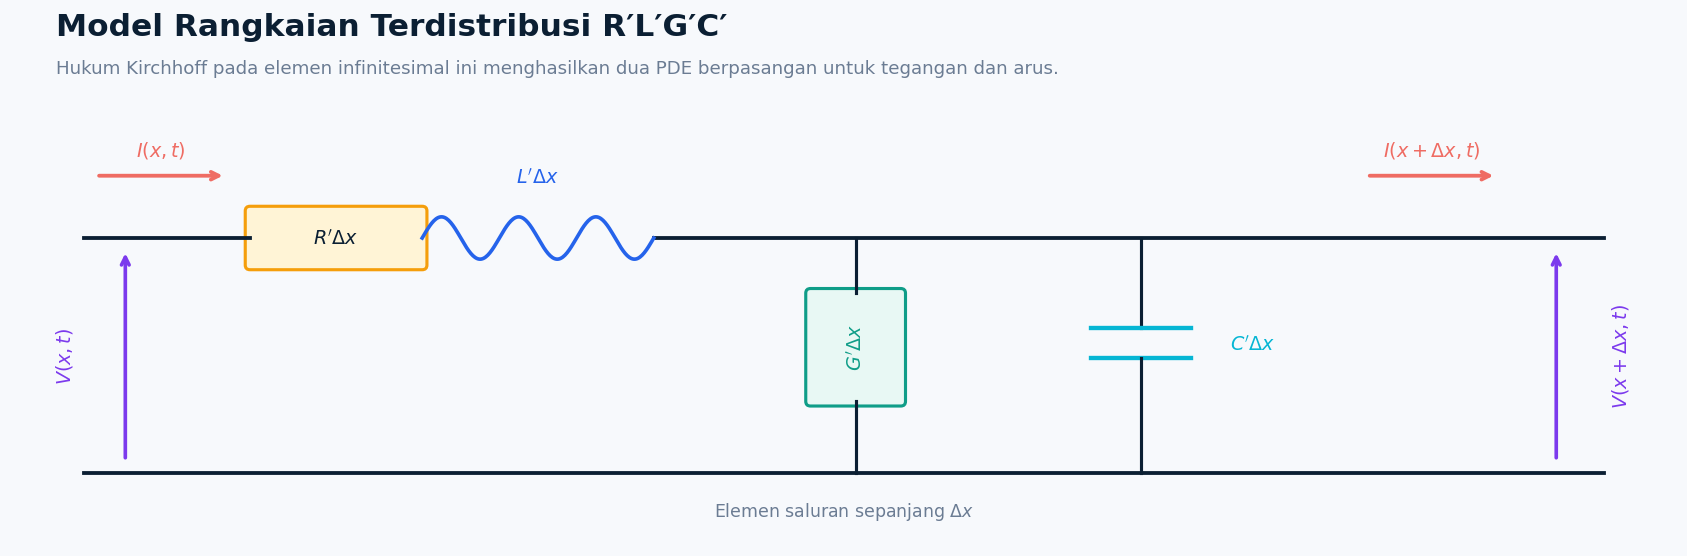

In [2]:
fig, ax = plt.subplots(figsize=(14, 4.7), facecolor=BRAND["paper"])
ax.set_xlim(0, 14)
ax.set_ylim(-0.35, 3.15)
ax.axis("off")

# Konduktor atas dan jalur referensi
ax.plot([0.6, 2.0], [2.25, 2.25], color=BRAND["ink"], linewidth=2.2)
ax.plot([5.4, 13.4], [2.25, 2.25], color=BRAND["ink"], linewidth=2.2)
ax.plot([0.6, 13.4], [0.25, 0.25], color=BRAND["ink"], linewidth=2.2)

# Resistor seri
resistor = patches.FancyBboxPatch(
    (2.0, 2.02), 1.45, 0.46, boxstyle="round,pad=0.04",
    facecolor="#FFF4D6", edgecolor=BRAND["amber"], linewidth=1.8
)
ax.add_patch(resistor)
ax.text(2.72, 2.25, r"$R'\Delta x$", ha="center", va="center",
        color=BRAND["ink"], fontweight="bold")

# Induktor seri konseptual
coil_x = np.linspace(3.45, 5.4, 220)
coil_y = 2.25 + 0.18 * np.sin(np.linspace(0, 6 * np.pi, 220))
ax.plot(coil_x, coil_y, color=BRAND["blue"], linewidth=2.1)
ax.text(4.42, 2.72, r"$L'\Delta x$", ha="center", color=BRAND["blue"],
        fontweight="bold")

# Cabang konduktansi
ax.plot([7.1, 7.1], [2.25, 1.78], color=BRAND["ink"], linewidth=1.8)
conductance = patches.FancyBboxPatch(
    (6.72, 0.86), 0.76, 0.92, boxstyle="round,pad=0.04",
    facecolor="#E8F8F4", edgecolor=BRAND["teal"], linewidth=1.8
)
ax.add_patch(conductance)
ax.text(7.1, 1.32, r"$G'\Delta x$", ha="center", va="center",
        rotation=90, color=BRAND["teal"], fontweight="bold")
ax.plot([7.1, 7.1], [0.86, 0.25], color=BRAND["ink"], linewidth=1.8)

# Cabang kapasitor
ax.plot([9.5, 9.5], [2.25, 1.48], color=BRAND["ink"], linewidth=1.8)
ax.plot([9.08, 9.92], [1.48, 1.48], color=BRAND["cyan"], linewidth=2.5)
ax.plot([9.08, 9.92], [1.23, 1.23], color=BRAND["cyan"], linewidth=2.5)
ax.plot([9.5, 9.5], [1.23, 0.25], color=BRAND["ink"], linewidth=1.8)
ax.text(10.25, 1.35, r"$C'\Delta x$", ha="left", va="center",
        color=BRAND["cyan"], fontweight="bold")

# Arah arus dan tegangan
ax.annotate("", xy=(1.8, 2.78), xytext=(0.7, 2.78),
            arrowprops=dict(arrowstyle="->", color=BRAND["coral"], linewidth=2.2))
ax.text(1.25, 2.95, r"$I(x,t)$", ha="center", color=BRAND["coral"],
        fontweight="bold")
ax.annotate("", xy=(12.5, 2.78), xytext=(11.4, 2.78),
            arrowprops=dict(arrowstyle="->", color=BRAND["coral"], linewidth=2.2))
ax.text(11.95, 2.95, r"$I(x+\Delta x,t)$", ha="center",
        color=BRAND["coral"], fontweight="bold")
ax.annotate("", xy=(0.95, 2.15), xytext=(0.95, 0.35),
            arrowprops=dict(arrowstyle="->", color=BRAND["purple"], linewidth=2.1))
ax.text(0.35, 1.25, r"$V(x,t)$", rotation=90, va="center",
        color=BRAND["purple"], fontweight="bold")
ax.annotate("", xy=(13.0, 2.15), xytext=(13.0, 0.35),
            arrowprops=dict(arrowstyle="->", color=BRAND["purple"], linewidth=2.1))
ax.text(13.45, 1.25, r"$V(x+\Delta x,t)$", rotation=90, va="center",
        color=BRAND["purple"], fontweight="bold")

ax.text(7.0, -0.12, r"Elemen saluran sepanjang $\Delta x$",
        ha="center", color=BRAND["muted"], fontsize=10)
figure_header(
    fig,
    "Model Rangkaian Terdistribusi R′L′G′C′",
    "Hukum Kirchhoff pada elemen infinitesimal ini menghasilkan dua PDE berpasangan untuk tegangan dan arus.",
)
fig.subplots_adjust(top=0.78, left=0.03, right=0.98, bottom=0.08)
plt.show()

# 2. Formulasi PDE dan Solusi Modal

## 2.1 Persamaan Telegraf orde satu

Dengan menerapkan KVL pada cabang seri dan KCL pada cabang shunt, lalu mengambil limit $\Delta x\to0$, saya memperoleh:

$$
\boxed{\frac{\partial V}{\partial x}
=-L'\frac{\partial I}{\partial t}-R'I}
$$

$$
\boxed{\frac{\partial I}{\partial x}
=-C'\frac{\partial V}{\partial t}-G'V}
$$

Persamaan pertama menyatakan bahwa gradien tegangan digunakan untuk membangun medan magnet dan mengatasi rugi resistif. Persamaan kedua menyatakan bahwa perubahan arus mengisi kapasitansi serta memasok arus bocor dielektrik.

## 2.2 Persamaan orde dua

Dengan mendiferensialkan persamaan pertama terhadap $x$ dan mensubstitusikan persamaan kedua:

$$
\boxed{
\frac{\partial^2 V}{\partial x^2}
=L'C'\frac{\partial^2 V}{\partial t^2}
+(R'C'+L'G')\frac{\partial V}{\partial t}
+R'G'V}
$$

Persamaan yang identik berlaku untuk $I$. Setelah dibagi $L'C'$:

$$
V_{tt}+2\alpha V_t+(\alpha^2-\beta^2)V=c^2V_{xx},
$$

dengan

$$
c=\frac{1}{\sqrt{L'C'}},\qquad
\alpha=\frac12\left(\frac{R'}{L'}+\frac{G'}{C'}\right),\qquad
\beta=\frac12\left(\frac{R'}{L'}-\frac{G'}{C'}\right).
$$

Besaran $c$ adalah kecepatan gelombang pada saluran ideal, $\alpha$ mengatur redaman temporal, sedangkan $\beta$ mengukur ketidakseimbangan rugi seri dan shunt.

## 2.3 Kondisi Heaviside dan solusi deret sinus

Kondisi bebas distorsi Heaviside adalah

$$
\frac{R'}{L'}=\frac{G'}{C'}
\quad\Longleftrightarrow\quad \beta=0.
$$

Pada kondisi ini sinyal tetap teredam, tetapi semua mode mengalami hubungan dispersi yang sama sehingga bentuk pulsa lebih terjaga.

Untuk batas hubung-singkat

$$
V(0,t)=V(\ell,t)=0,
$$

saya menulis $V=e^{-\alpha t}W$. Persamaan berubah menjadi

$$
W_{tt}=c^2W_{xx}+\beta^2W.
$$

Dengan $k_n=n\pi/\ell$, frekuensi mode teredam adalah

$$
\boxed{\omega_n=\sqrt{c^2k_n^2-\beta^2}}.
$$

Jika $V(x,0)=f(x)$ dan $V_t(x,0)=g(x)$, maka untuk mode osilatori:

$$
V(x,t)=e^{-\alpha t}\sum_{n=1}^{\infty}
\left[
a_n\cos(\omega_nt)
+\frac{g_n+\alpha a_n}{\omega_n}\sin(\omega_nt)
\right]\sin(k_nx),
$$

$$
a_n=\frac{2}{\ell}\int_0^\ell f(x)\sin(k_nx)\,dx,\qquad
g_n=\frac{2}{\ell}\int_0^\ell g(x)\sin(k_nx)\,dx.
$$

Jika $c^2k_n^2-\beta^2<0$, fungsi sinus/kosinus diganti fungsi hiperbolik. Rumus ini saya gunakan untuk memahami struktur modal; simulasi utama diselesaikan langsung dari sistem orde satu agar $V$ dan $I$ diperoleh bersama.

# 3. Diskretisasi Finite-Difference Time-Domain

Saya menggunakan grid berselang-seling:

- $V_j^n$ berada pada titik $x_j=j\Delta x$ dan waktu $t_n=n\Delta t$;
- $I_{j+1/2}^{n+1/2}$ berada di tengah sel dan setengah langkah waktu.

Struktur ini menyelaraskan posisi gradien diskret dengan posisi variabel yang diperbarui. Dengan diskretisasi terpusat untuk rugi, koefisien pembaruan menjadi

$$
I_{j+1/2}^{n+1/2}
=a_I I_{j+1/2}^{n-1/2}
-b_I\left(V_{j+1}^n-V_j^n\right),
$$

$$
a_I=\frac{1-\frac{R'\Delta t}{2L'}}{1+\frac{R'\Delta t}{2L'}},
\qquad
b_I=\frac{\Delta t/(L'\Delta x)}
{1+\frac{R'\Delta t}{2L'}},
$$

lalu

$$
V_j^{n+1}
=a_VV_j^n-b_V
\left(I_{j+1/2}^{n+1/2}-I_{j-1/2}^{n+1/2}\right),
$$

$$
a_V=\frac{1-\frac{G'\Delta t}{2C'}}{1+\frac{G'\Delta t}{2C'}},
\qquad
b_V=\frac{\Delta t/(C'\Delta x)}
{1+\frac{G'\Delta t}{2C'}}.
$$

## 3.1 Syarat stabilitas

Untuk bagian gelombang eksplisit, bilangan Courant harus memenuhi

$$
\boxed{S=\frac{c\Delta t}{\Delta x}\le1}.
$$

Saya memilih $S_{\mathrm{target}}=0.92$ agar terdapat margin terhadap batas stabilitas.

**Urutan algoritma setiap langkah waktu:**

1. perbarui seluruh arus pada titik setengah-grid;
2. hitung arus pada waktu integer untuk energi dan visualisasi;
3. perbarui tegangan interior;
4. terapkan kondisi batas $V_0=V_{N_x-1}=0$;
5. simpan diagnostik energi dan daya rugi.

# 4. Konfigurasi dan Eksekusi Simulasi

Saya menggunakan nilai yang menyerupai saluran berimpedansi karakteristik sekitar $50\,\Omega$. Skala waktunya berada pada mikrodetik karena panjang saluran adalah satu kilometer dan kecepatan rambat mendekati $2\times10^8\,\mathrm{m/s}$.

Besaran,Nilai,Satuan
Panjang,1000,m
R′,0.02,Ω/m
L′,2.5e-07,H/m
G′,1e-06,S/m
C′,1e-10,F/m
Kecepatan c,2e+08,m/s
Impedansi Z₀,50,Ω
Redaman α,45000,s⁻¹
Ketidakseimbangan β,35000,s⁻¹
Waktu lintas,5e-06,s


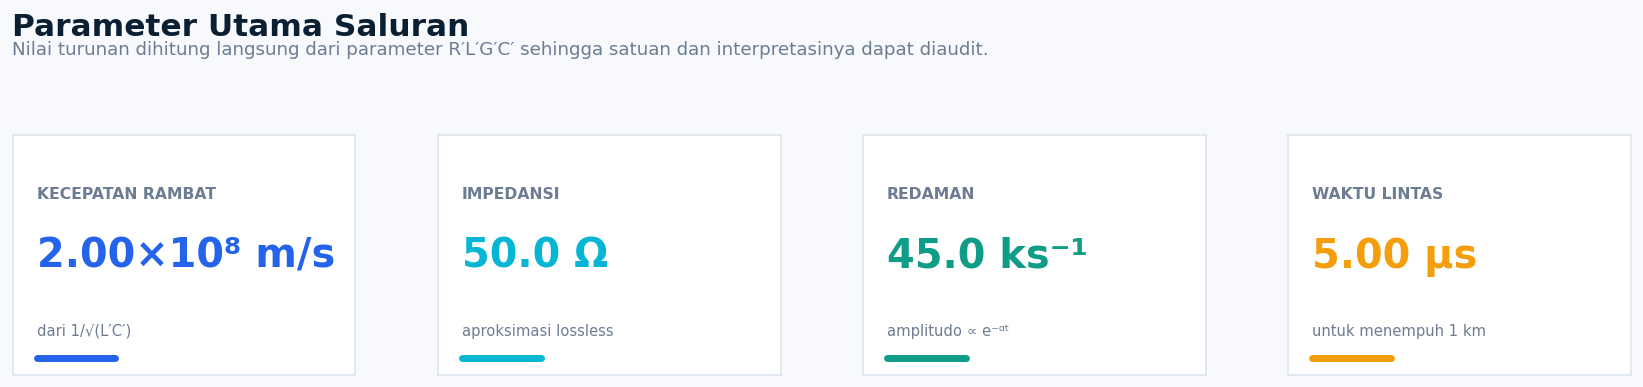

In [3]:
# Parameter fisik per satuan panjang
LENGTH = 1_000.0          # m
L_PER_M = 250e-9          # H/m
C_PER_M = 100e-12         # F/m
R_PER_M = 0.020           # ohm/m
G_PER_M = 1.0e-6          # S/m

# Parameter grid
NX = 241
T_END = 12e-6             # s
COURANT_TARGET = 0.92

c_wave = 1 / np.sqrt(L_PER_M * C_PER_M)
z0 = np.sqrt(L_PER_M / C_PER_M)
alpha = 0.5 * (R_PER_M / L_PER_M + G_PER_M / C_PER_M)
beta = 0.5 * (R_PER_M / L_PER_M - G_PER_M / C_PER_M)
transit_time = LENGTH / c_wave

parameter_table = pd.DataFrame({
    "Besaran": ["Panjang", "R′", "L′", "G′", "C′", "Kecepatan c",
                "Impedansi Z₀", "Redaman α", "Ketidakseimbangan β", "Waktu lintas"],
    "Nilai": [LENGTH, R_PER_M, L_PER_M, G_PER_M, C_PER_M, c_wave,
              z0, alpha, beta, transit_time],
    "Satuan": ["m", "Ω/m", "H/m", "S/m", "F/m", "m/s",
               "Ω", "s⁻¹", "s⁻¹", "s"],
})
display(polish_table(parameter_table, {"Nilai": "{:.6g}"}, hide_index=True))

fig = plt.figure(figsize=(14, 3.2), facecolor=BRAND["paper"])
gs = fig.add_gridspec(1, 4, wspace=0.24)
cards = [
    ("Kecepatan rambat", f"{c_wave/1e8:.2f}×10⁸ m/s", "dari 1/√(L′C′)", BRAND["blue"]),
    ("Impedansi", f"{z0:.1f} Ω", "aproksimasi lossless", BRAND["cyan"]),
    ("Redaman", f"{alpha/1e3:.1f} ks⁻¹", "amplitudo ∝ e⁻ᵅᵗ", BRAND["teal"]),
    ("Waktu lintas", f"{transit_time*1e6:.2f} μs", "untuk menempuh 1 km", BRAND["amber"]),
]
for idx, card in enumerate(cards):
    metric_card(fig.add_subplot(gs[0, idx]), *card)
figure_header(
    fig,
    "Parameter Utama Saluran",
    "Nilai turunan dihitung langsung dari parameter R′L′G′C′ sehingga satuan dan interpretasinya dapat diaudit.",
)
fig.subplots_adjust(top=0.68, left=0.055, right=0.98, bottom=0.08)
plt.show()

In [4]:
def simulate_transmission_line(
    length=1_000.0,
    nx=241,
    t_end=12e-6,
    courant=0.92,
    resistance=0.020,
    inductance=250e-9,
    conductance=1e-6,
    capacitance=100e-12,
    initial_voltage=None,
    initial_current=None,
):
    """FDTD staggered-grid untuk Persamaan Telegraf dengan batas V=0."""
    x = np.linspace(0.0, length, nx)
    dx = x[1] - x[0]
    x_half = 0.5 * (x[:-1] + x[1:])

    c = 1 / np.sqrt(inductance * capacitance)
    dt_limit = courant * dx / c
    nt = int(np.ceil(t_end / dt_limit))
    dt = t_end / nt
    times = np.arange(nt + 1) * dt

    V = (np.zeros(nx) if initial_voltage is None
         else np.asarray(initial_voltage(x), dtype=float).copy())
    I0 = (np.zeros(nx - 1) if initial_current is None
          else np.asarray(initial_current(x_half), dtype=float).copy())
    V[0] = V[-1] = 0.0

    # Inisialisasi I pada t=-dt/2 agar leapfrog berorde dua saat I(x,0) diketahui.
    grad_v = (V[1:] - V[:-1]) / dx
    I_minus = I0 + 0.5 * dt * (grad_v + resistance * I0) / inductance

    a_i = (1 - resistance * dt / (2 * inductance)) / (
        1 + resistance * dt / (2 * inductance)
    )
    b_i = (dt / (inductance * dx)) / (
        1 + resistance * dt / (2 * inductance)
    )
    a_v = (1 - conductance * dt / (2 * capacitance)) / (
        1 + conductance * dt / (2 * capacitance)
    )
    b_v = (dt / (capacitance * dx)) / (
        1 + conductance * dt / (2 * capacitance)
    )

    voltage_history = np.empty((nt + 1, nx))
    current_history = np.empty((nt + 1, nx - 1))
    energy = np.empty(nt + 1)
    power_loss = np.empty(nt + 1)

    for n in range(nt + 1):
        I_plus = a_i * I_minus - b_i * (V[1:] - V[:-1])
        I_integer = 0.5 * (I_minus + I_plus)

        voltage_history[n] = V
        current_history[n] = I_integer
        energy[n] = (
            0.5 * capacitance * trapz(V**2, x)
            + 0.5 * inductance * np.sum(I_integer**2) * dx
        )
        power_loss[n] = (
            conductance * trapz(V**2, x)
            + resistance * np.sum(I_integer**2) * dx
        )

        if n == nt:
            break

        V_new = V.copy()
        V_new[1:-1] = (
            a_v * V[1:-1]
            - b_v * (I_plus[1:] - I_plus[:-1])
        )
        V_new[0] = V_new[-1] = 0.0
        V = V_new
        I_minus = I_plus

    return {
        "x": x,
        "x_half": x_half,
        "t": times,
        "V": voltage_history,
        "I": current_history,
        "energy": energy,
        "power_loss": power_loss,
        "dx": dx,
        "dt": dt,
        "c": c,
        "courant": c * dt / dx,
        "coefficients": {"a_i": a_i, "b_i": b_i, "a_v": a_v, "b_v": b_v},
    }


print("Fungsi solver FDTD berhasil didefinisikan.")

Fungsi solver FDTD berhasil didefinisikan.


## 4.1 Kondisi awal

Saya memilih pulsa Gaussian satu volt di tengah saluran:

$$
V(x,0)=\exp\left[-\left(\frac{x-\ell/2}{0.06\ell}\right)^2\right],
\qquad I(x,0)=0.
$$

Karena arus awal nol, profil tegangan ini akan membelah menjadi dua gelombang yang merambat berlawanan arah. Ujung hubung-singkat memaksa $V=0$ dan menghasilkan refleksi dengan pembalikan tanda tegangan.

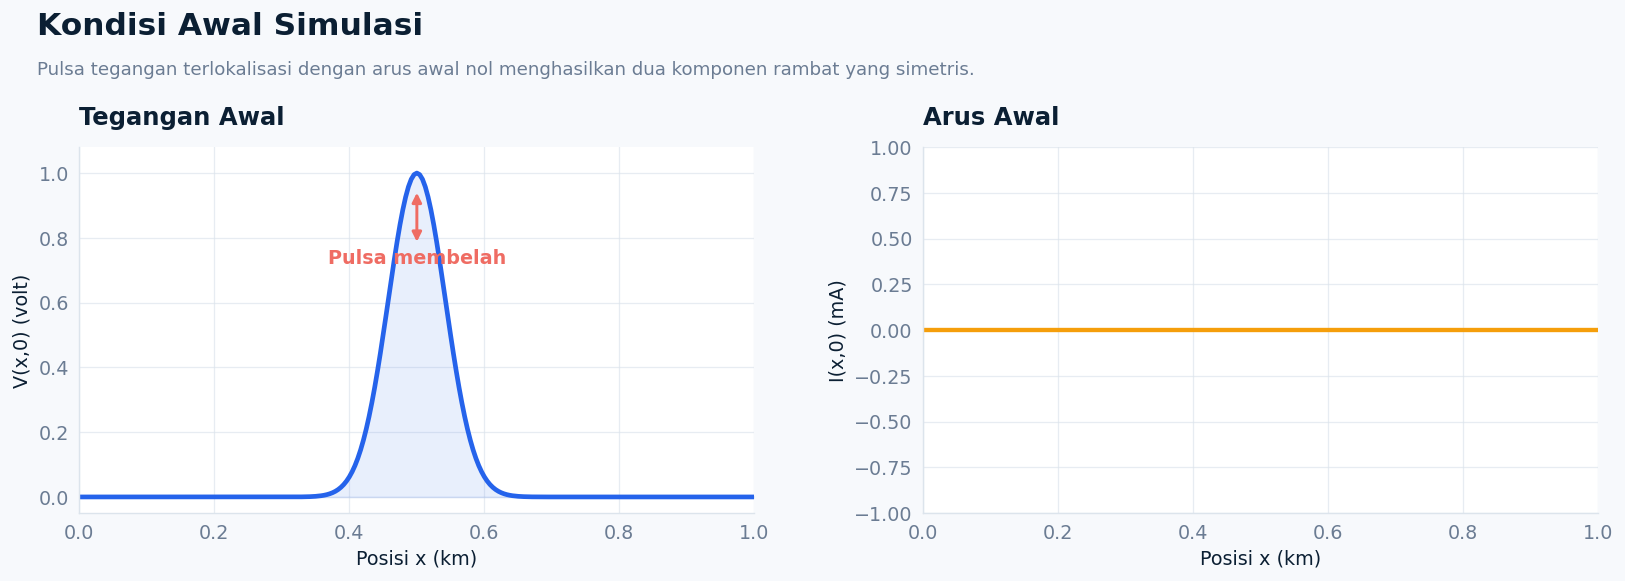

In [5]:
pulse_width = 0.06 * LENGTH

def initial_voltage(x):
    return np.exp(-((x - 0.5 * LENGTH) / pulse_width) ** 2)

def initial_current(x_half):
    return np.zeros_like(x_half)

x_preview = np.linspace(0, LENGTH, NX)
x_half_preview = 0.5 * (x_preview[:-1] + x_preview[1:])

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), facecolor=BRAND["paper"])
axes[0].plot(x_preview / 1e3, initial_voltage(x_preview),
             color=BRAND["blue"], linewidth=2.7)
axes[0].fill_between(x_preview / 1e3, initial_voltage(x_preview), 0,
                     color=BRAND["blue"], alpha=0.10)
axes[0].annotate("Pulsa membelah", xy=(0.5, 0.95), xytext=(0.5, 0.72),
                 arrowprops=dict(arrowstyle="<|-|>", color=BRAND["coral"],
                                 linewidth=1.7),
                 ha="center", color=BRAND["coral"], fontweight="bold")
axes[0].set_title("Tegangan Awal", loc="left")
axes[0].set_xlabel("Posisi x (km)")
axes[0].set_ylabel("V(x,0) (volt)")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(-0.05, 1.08)
style_axis(axes[0], "both")

axes[1].plot(x_half_preview / 1e3, initial_current(x_half_preview) * 1e3,
             color=BRAND["amber"], linewidth=2.5)
axes[1].set_title("Arus Awal", loc="left")
axes[1].set_xlabel("Posisi x (km)")
axes[1].set_ylabel("I(x,0) (mA)")
axes[1].set_xlim(0, 1)
axes[1].set_ylim(-1, 1)
style_axis(axes[1], "both")

figure_header(
    fig,
    "Kondisi Awal Simulasi",
    "Pulsa tegangan terlokalisasi dengan arus awal nol menghasilkan dua komponen rambat yang simetris.",
)
fig.subplots_adjust(top=0.76, left=0.08, right=0.98, bottom=0.15, wspace=0.25)
plt.show()

In [6]:
result = simulate_transmission_line(
    length=LENGTH,
    nx=NX,
    t_end=T_END,
    courant=COURANT_TARGET,
    resistance=R_PER_M,
    inductance=L_PER_M,
    conductance=G_PER_M,
    capacitance=C_PER_M,
    initial_voltage=initial_voltage,
    initial_current=initial_current,
)

grid_summary = pd.DataFrame({
    "Besaran": ["Jumlah node tegangan", "Jumlah langkah waktu", "Δx",
                "Δt", "Courant aktual", "Batas stabilitas"],
    "Nilai": [NX, len(result["t"]) - 1, result["dx"], result["dt"],
              result["courant"], 1.0],
    "Satuan": ["node", "langkah", "m", "s", "—", "—"],
})
display(polish_table(grid_summary, {"Nilai": "{:.6g}"}, hide_index=True))

assert result["courant"] <= 1.0
assert np.allclose(result["V"][:, 0], 0.0)
assert np.allclose(result["V"][:, -1], 0.0)
assert np.isfinite(result["V"]).all() and np.isfinite(result["I"]).all()

print(f"Ukuran histori V : {result['V'].shape}")
print(f"Ukuran histori I : {result['I'].shape}")
print(f"Courant aktual   : {result['courant']:.6f} <= 1")
print("Pemeriksaan stabilitas, batas, dan nilai finite: LULUS")

Besaran,Nilai,Satuan
Jumlah node tegangan,241,node
Jumlah langkah waktu,627,langkah
Δx,4.16667,m
Δt,1.91388e-08,s
Courant aktual,0.91866,—
Batas stabilitas,1,—


Ukuran histori V : (628, 241)
Ukuran histori I : (628, 240)
Courant aktual   : 0.918660 <= 1
Pemeriksaan stabilitas, batas, dan nilai finite: LULUS


# 5. Visualisasi Hasil Simulasi

Saya membaca hasil dalam tiga sudut pandang:

1. **snapshot ruang** untuk melihat posisi pulsa pada beberapa waktu;
2. **peta ruang–waktu** untuk melihat lintasan karakteristik dan refleksi;
3. **animasi** untuk mengikuti hubungan tegangan–arus secara intuitif.

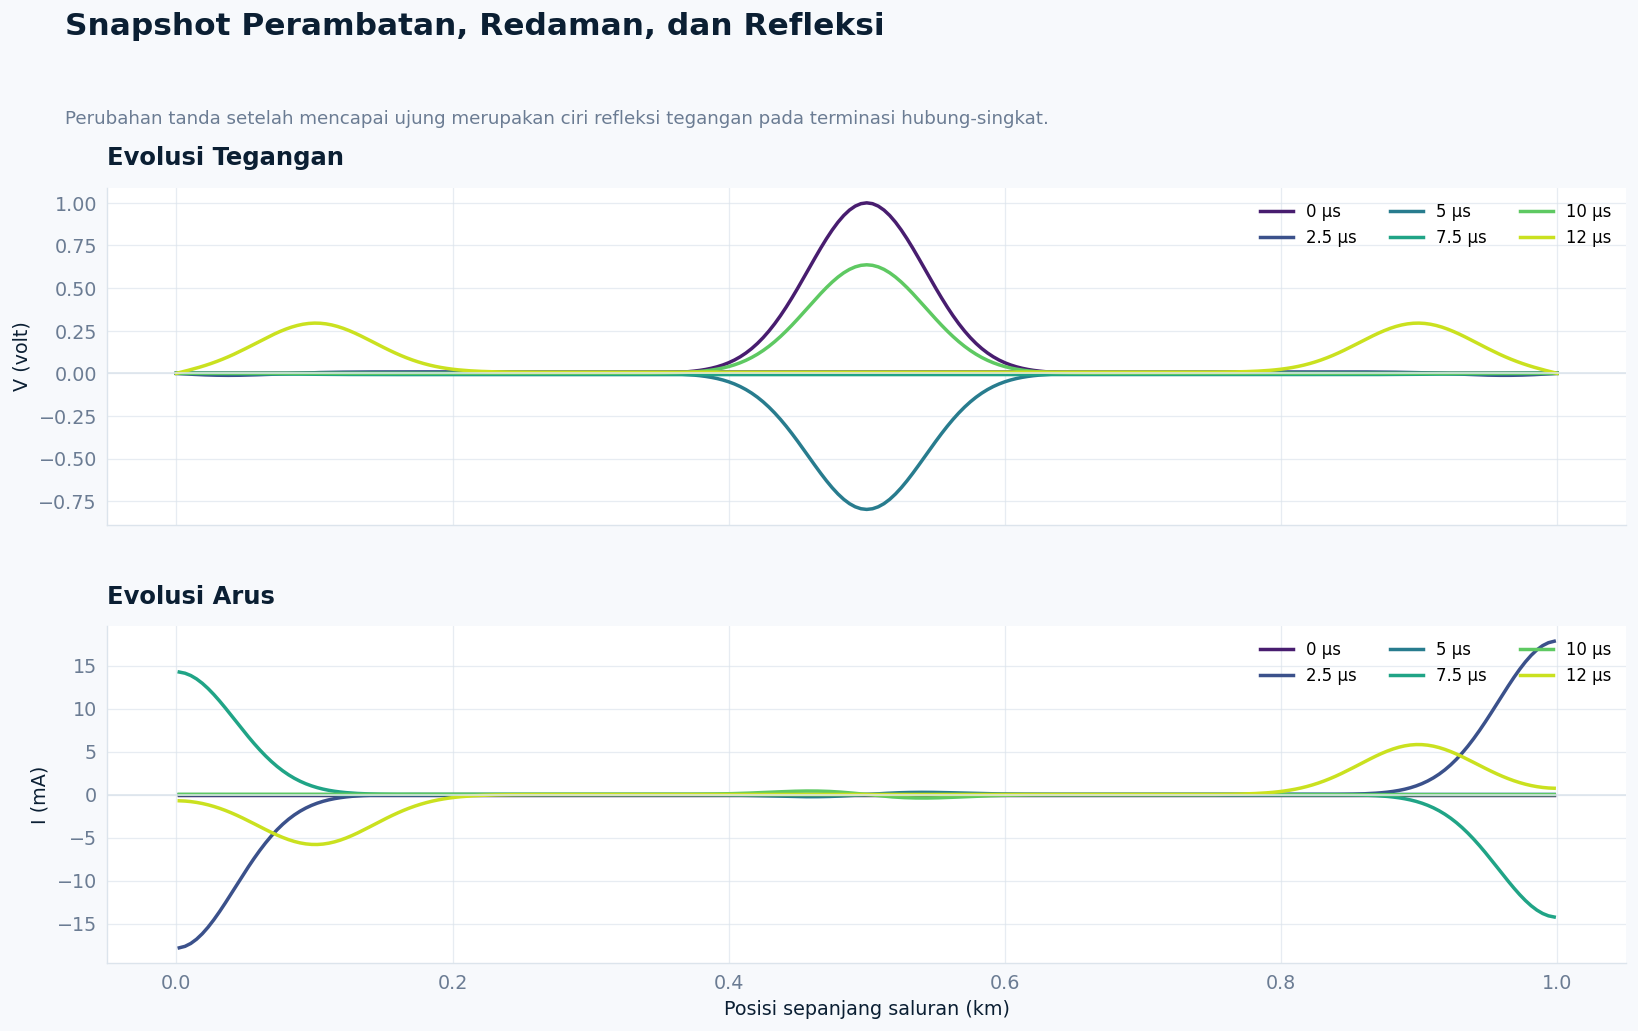

In [7]:
snapshot_us = [0.0, 2.5, 5.0, 7.5, 10.0, 12.0]
snapshot_indices = [int(np.argmin(np.abs(result["t"] - time_us * 1e-6)))
                    for time_us in snapshot_us]
snapshot_colors = plt.cm.viridis(np.linspace(0.08, 0.92, len(snapshot_indices)))

fig, axes = plt.subplots(2, 1, figsize=(13.5, 8.5), sharex=True,
                         facecolor=BRAND["paper"])
for idx, time_us, color in zip(snapshot_indices, snapshot_us, snapshot_colors):
    axes[0].plot(result["x"] / 1e3, result["V"][idx],
                 color=color, linewidth=2.0, label=f"{time_us:g} μs")
    axes[1].plot(result["x_half"] / 1e3, result["I"][idx] * 1e3,
                 color=color, linewidth=2.0, label=f"{time_us:g} μs")

axes[0].axhline(0, color=BRAND["grid"], linewidth=0.9)
axes[0].set_title("Evolusi Tegangan", loc="left")
axes[0].set_ylabel("V (volt)")
axes[0].legend(ncol=3, loc="upper right")
style_axis(axes[0], "both")

axes[1].axhline(0, color=BRAND["grid"], linewidth=0.9)
axes[1].set_title("Evolusi Arus", loc="left")
axes[1].set_xlabel("Posisi sepanjang saluran (km)")
axes[1].set_ylabel("I (mA)")
axes[1].legend(ncol=3, loc="upper right")
style_axis(axes[1], "both")

figure_header(
    fig,
    "Snapshot Perambatan, Redaman, dan Refleksi",
    "Perubahan tanda setelah mencapai ujung merupakan ciri refleksi tegangan pada terminasi hubung-singkat.",
)
fig.subplots_adjust(top=0.82, left=0.08, right=0.98, bottom=0.09, hspace=0.30)
plt.show()

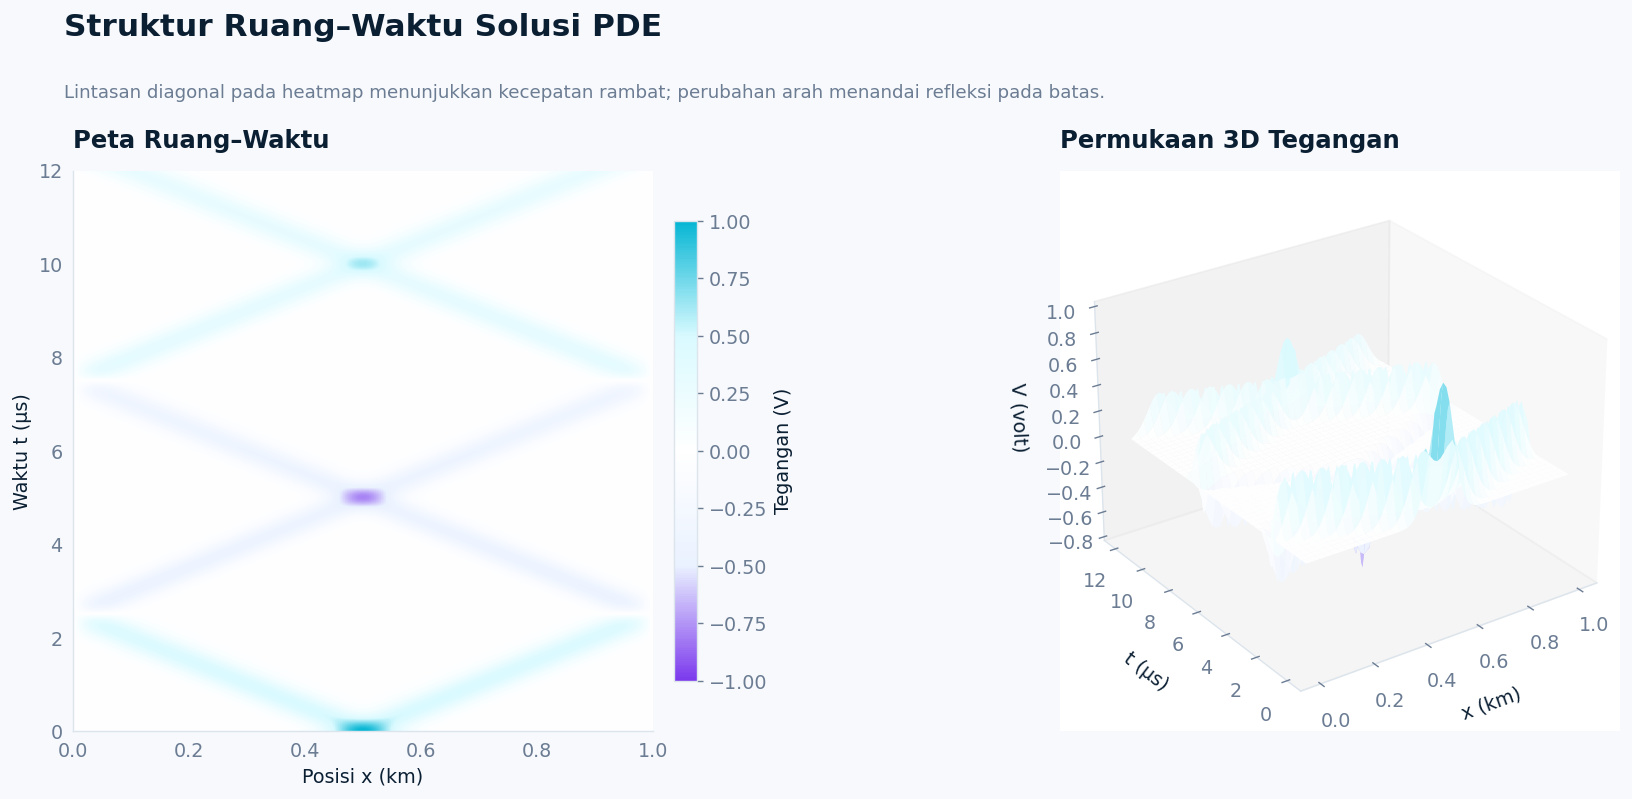

In [8]:
time_us = result["t"] * 1e6
position_km = result["x"] / 1e3
vmax = np.max(np.abs(result["V"]))
voltage_cmap = LinearSegmentedColormap.from_list(
    "electric_diverging",
    [BRAND["purple"], "#EAF2FF", BRAND["white"], "#D9FAFF", BRAND["cyan"]]
)

fig = plt.figure(figsize=(15, 6.5), facecolor=BRAND["paper"])
gs = fig.add_gridspec(1, 2, width_ratios=[1.05, 1.25], wspace=0.18)

ax1 = fig.add_subplot(gs[0, 0])
image = ax1.imshow(
    result["V"], origin="lower", aspect="auto",
    extent=[position_km.min(), position_km.max(), time_us.min(), time_us.max()],
    cmap=voltage_cmap, vmin=-vmax, vmax=vmax,
)
ax1.set_title("Peta Ruang–Waktu", loc="left")
ax1.set_xlabel("Posisi x (km)")
ax1.set_ylabel("Waktu t (μs)")
cbar1 = fig.colorbar(image, ax=ax1, shrink=0.82, pad=0.03)
cbar1.set_label("Tegangan (V)")
style_axis(ax1, grid=None)

ax2 = fig.add_subplot(gs[0, 1], projection="3d")
t_stride = slice(None, None, 5)
x_stride = slice(None, None, 3)
X_surface, T_surface = np.meshgrid(
    position_km[x_stride], time_us[t_stride]
)
surface = ax2.plot_surface(
    X_surface, T_surface, result["V"][t_stride, x_stride],
    cmap=voltage_cmap, vmin=-vmax, vmax=vmax,
    linewidth=0, antialiased=True, alpha=0.96,
)
ax2.set_title("Permukaan 3D Tegangan", loc="left")
ax2.set_xlabel("x (km)", labelpad=8)
ax2.set_ylabel("t (μs)", labelpad=8)
ax2.set_zlabel("V (volt)", labelpad=7)
ax2.view_init(elev=27, azim=-125)
ax2.grid(False)

figure_header(
    fig,
    "Struktur Ruang–Waktu Solusi PDE",
    "Lintasan diagonal pada heatmap menunjukkan kecepatan rambat; perubahan arah menandai refleksi pada batas.",
)
fig.subplots_adjust(top=0.79, left=0.06, right=0.96, bottom=0.10)
plt.show()

## 5.1 Animasi konseptual tegangan dan arus

Animasi berikut adalah bagian penting dari interpretasi, bukan sekadar dekorasi:

- kurva atas memperlihatkan tegangan yang membelah dan memantul;
- kurva bawah memperlihatkan arus, termasuk perubahan arah aliran;
- label waktu dan persentase energi membantu menghubungkan gerak gelombang dengan disipasi;
- kontrol di bawah animasi dapat digunakan untuk play, pause, atau memilih frame.

> Jika kontrol belum muncul saat file pertama kali dibuka, tandai notebook sebagai **trusted** atau jalankan kembali sel animasi.

In [9]:
frame_indices = np.unique(
    np.linspace(0, len(result["t"]) - 1, 64, dtype=int)
)

fig_anim, (ax_v, ax_i) = plt.subplots(
    2, 1, figsize=(9.8, 5.8), sharex=True, dpi=90,
    facecolor=BRAND["paper"]
)
line_v, = ax_v.plot([], [], color=BRAND["blue"], linewidth=2.6)
line_i, = ax_i.plot([], [], color=BRAND["amber"], linewidth=2.4)
ax_v.axhline(0, color=BRAND["grid"], linewidth=0.9)
ax_i.axhline(0, color=BRAND["grid"], linewidth=0.9)

ax_v.set_xlim(0, LENGTH / 1e3)
ax_v.set_ylim(-1.05, 1.05)
ax_i.set_xlim(0, LENGTH / 1e3)
current_limit_ma = 1.15 * np.max(np.abs(result["I"])) * 1e3
ax_i.set_ylim(-current_limit_ma, current_limit_ma)
ax_v.set_ylabel("V (volt)")
ax_i.set_ylabel("I (mA)")
ax_i.set_xlabel("Posisi x (km)")
ax_v.set_title("Tegangan sepanjang saluran", loc="left", fontsize=12)
ax_i.set_title("Arus sepanjang saluran", loc="left", fontsize=12)
style_axis(ax_v, "both")
style_axis(ax_i, "both")

status_text = ax_v.text(
    0.99, 0.91, "", transform=ax_v.transAxes,
    ha="right", va="top", color=BRAND["ink"], fontsize=9.5,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white",
              edgecolor=BRAND["grid"], alpha=0.94)
)

def update_animation(frame_number):
    idx = frame_indices[frame_number]
    line_v.set_data(result["x"] / 1e3, result["V"][idx])
    line_i.set_data(result["x_half"] / 1e3, result["I"][idx] * 1e3)
    energy_pct = 100 * result["energy"][idx] / result["energy"][0]
    status_text.set_text(
        f"t = {result['t'][idx] * 1e6:5.2f} μs\n"
        f"E/E₀ = {energy_pct:5.1f}%"
    )
    return line_v, line_i, status_text

conceptual_animation = animation.FuncAnimation(
    fig_anim, update_animation, frames=len(frame_indices),
    interval=75, blit=False, repeat=True
)
fig_anim.subplots_adjust(top=0.92, left=0.10, right=0.98, bottom=0.12, hspace=0.35)
plt.close(fig_anim)

display(HTML(conceptual_animation.to_jshtml(fps=15, default_mode="loop")))
print(f"Animasi tertanam: {len(frame_indices)} frame dengan kontrol interaktif.")

Animasi tertanam: 64 frame dengan kontrol interaktif.


# 6. Neraca Energi Elektromagnetik

Energi tersimpan per satuan penampang pada model saluran adalah

$$
\boxed{
\mathcal E(t)=\frac12\int_0^\ell
\left(C'V^2+L'I^2\right)\,dx}.
$$

Dengan mengalikan kedua Persamaan Telegraf oleh $V$ dan $I$, lalu menjumlahkan:

$$
\frac{d\mathcal E}{dt}
=-\int_0^\ell\left(G'V^2+R'I^2\right)\,dx
-[VI]_0^\ell.
$$

Suku integral adalah daya yang berubah menjadi panas atau bocor melalui dielektrik. Karena $V=0$ pada kedua ujung, fluks daya batas $[VI]_0^\ell$ bernilai nol. Dengan demikian,

$$
\mathcal E(t)+\int_0^tP_{\mathrm{loss}}(\tau)\,d\tau
\approx \mathcal E(0).
$$

Relasi ini memberi uji fisika yang lebih kuat daripada sekadar melihat amplitudo mengecil.

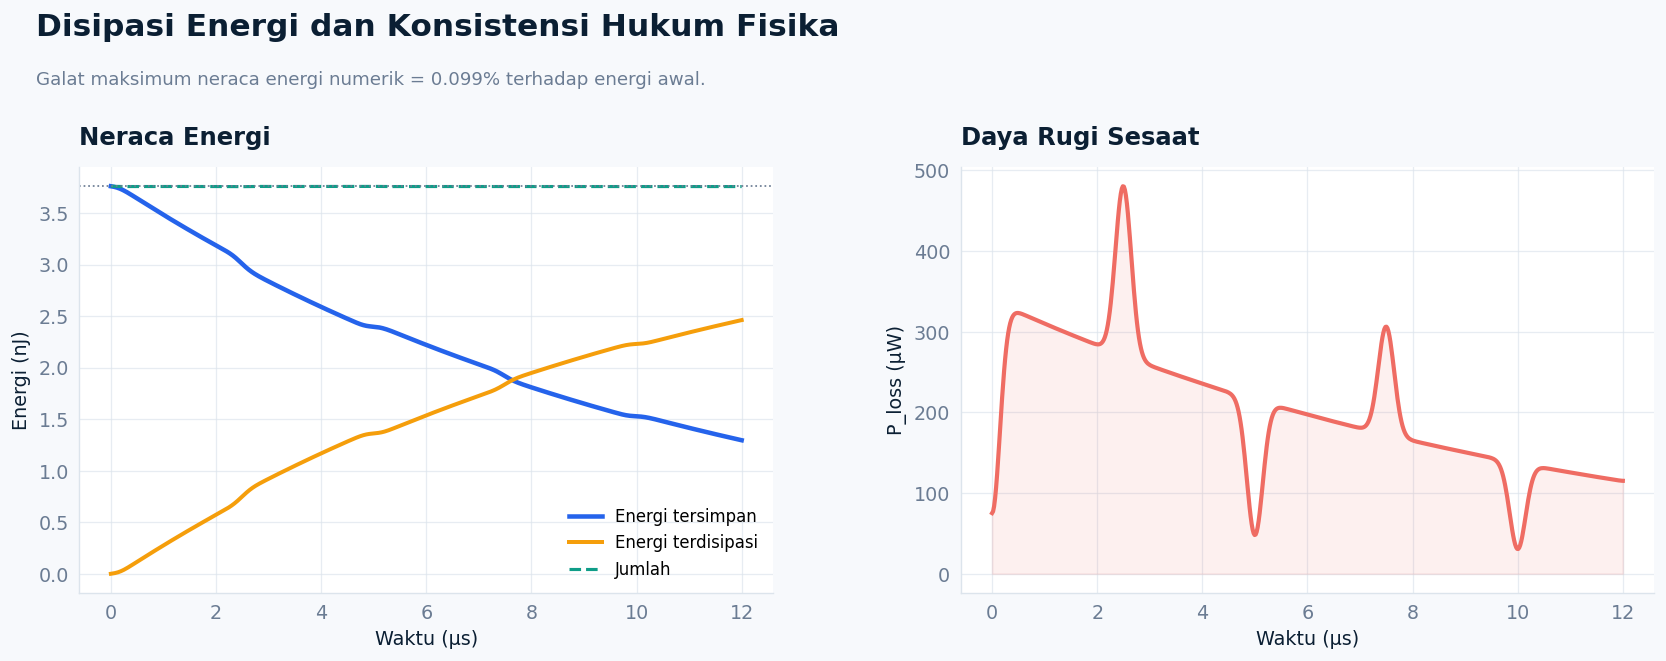

Energi awal             : 3.759942 nJ
Energi akhir            : 1.295613 nJ
Energi tersisa          : 34.46%
Galat maksimum neraca   : 0.0993%
Energi monoton menurun  : True


In [10]:
cumulative_loss = np.zeros_like(result["t"])
cumulative_loss[1:] = np.cumsum(
    0.5 * (result["power_loss"][1:] + result["power_loss"][:-1])
    * np.diff(result["t"])
)
energy_balance_residual = (
    result["energy"] + cumulative_loss - result["energy"][0]
)
relative_balance_error = np.max(np.abs(energy_balance_residual)) / result["energy"][0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), facecolor=BRAND["paper"])

axes[0].plot(time_us, result["energy"] * 1e9,
             color=BRAND["blue"], linewidth=2.6, label="Energi tersimpan")
axes[0].plot(time_us, cumulative_loss * 1e9,
             color=BRAND["amber"], linewidth=2.3, label="Energi terdisipasi")
axes[0].plot(
    time_us, (result["energy"] + cumulative_loss) * 1e9,
    color=BRAND["teal"], linewidth=1.8, linestyle="--",
    label="Jumlah"
)
axes[0].axhline(result["energy"][0] * 1e9, color=BRAND["muted"],
                linewidth=1.0, linestyle=":")
axes[0].set_title("Neraca Energi", loc="left")
axes[0].set_xlabel("Waktu (μs)")
axes[0].set_ylabel("Energi (nJ)")
axes[0].legend()
style_axis(axes[0], "both")

axes[1].plot(time_us, result["power_loss"] * 1e6,
             color=BRAND["coral"], linewidth=2.4)
axes[1].fill_between(time_us, result["power_loss"] * 1e6, 0,
                     color=BRAND["coral"], alpha=0.10)
axes[1].set_title("Daya Rugi Sesaat", loc="left")
axes[1].set_xlabel("Waktu (μs)")
axes[1].set_ylabel("P_loss (μW)")
style_axis(axes[1], "both")

figure_header(
    fig,
    "Disipasi Energi dan Konsistensi Hukum Fisika",
    f"Galat maksimum neraca energi numerik = {relative_balance_error:.3%} terhadap energi awal.",
)
fig.subplots_adjust(top=0.76, left=0.08, right=0.98, bottom=0.14, wspace=0.27)
plt.show()

print(f"Energi awal             : {result['energy'][0] * 1e9:.6f} nJ")
print(f"Energi akhir            : {result['energy'][-1] * 1e9:.6f} nJ")
print(f"Energi tersisa          : {result['energy'][-1] / result['energy'][0]:.2%}")
print(f"Galat maksimum neraca   : {relative_balance_error:.4%}")
print(f"Energi monoton menurun  : {np.all(np.diff(result['energy']) <= 1e-15)}")

In [11]:
display(Markdown(
    f"**Interpretasi saya:** setelah {T_END * 1e6:.1f} μs, energi yang masih tersimpan "
    f"adalah **{result['energy'][-1] / result['energy'][0]:.2%}** dari energi awal. "
    f"Neraca energi tertutup dengan galat maksimum **{relative_balance_error:.4%}**, "
    "sehingga penurunan energi dapat dijelaskan oleh rugi resistif dan kebocoran "
    "dielektrik, bukan oleh ketidakstabilan numerik."
))

**Interpretasi saya:** setelah 12.0 μs, energi yang masih tersimpan adalah **34.46%** dari energi awal. Neraca energi tertutup dengan galat maksimum **0.0993%**, sehingga penurunan energi dapat dijelaskan oleh rugi resistif dan kebocoran dielektrik, bukan oleh ketidakstabilan numerik.

# 7. Validasi terhadap Solusi Analitik

Saya menghilangkan rugi dengan $R'=G'=0$ dan memakai satu mode:

$$
V(x,0)=\sin\left(\frac{\pi x}{\ell}\right),\qquad I(x,0)=0.
$$

Solusi eksaknya adalah

$$
V_{\mathrm{exact}}(x,t)=
\sin(kx)\cos(ckt),
$$

$$
I_{\mathrm{exact}}(x,t)=
-\frac{1}{Z_0}\cos(kx)\sin(ckt),
\qquad k=\frac{\pi}{\ell}.
$$

Galat relatif $L_2$ saya definisikan sebagai

$$
\varepsilon_2=
\sqrt{\frac{\int|u_h-u|^2dx}{\int|u|^2dx}}.
$$

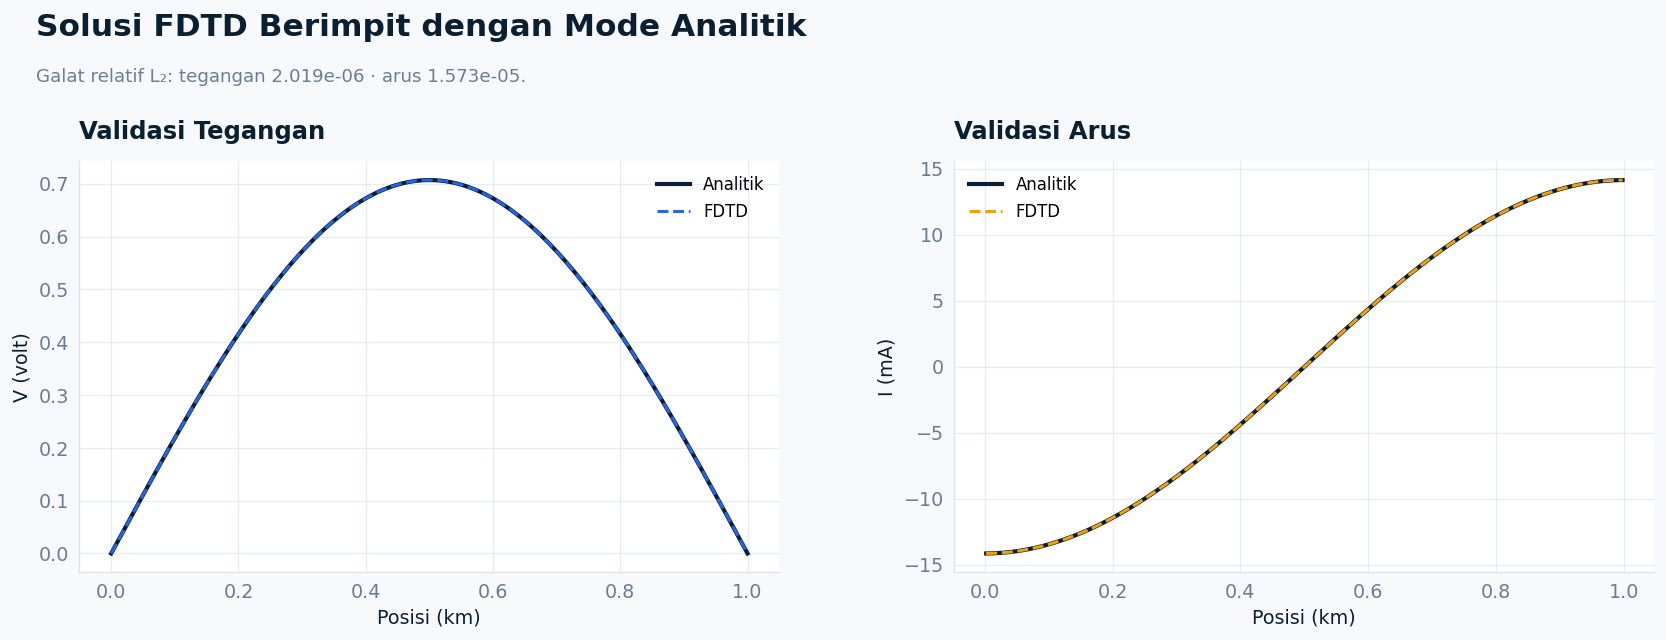

In [12]:
validation_time = 1.25e-6
k_mode = np.pi / LENGTH

validation = simulate_transmission_line(
    length=LENGTH,
    nx=NX,
    t_end=validation_time,
    courant=0.80,
    resistance=0.0,
    inductance=L_PER_M,
    conductance=0.0,
    capacitance=C_PER_M,
    initial_voltage=lambda x: np.sin(k_mode * x),
    initial_current=lambda x_half: np.zeros_like(x_half),
)

t_final = validation["t"][-1]
v_exact = np.sin(k_mode * validation["x"]) * np.cos(c_wave * k_mode * t_final)
i_exact = (
    -np.cos(k_mode * validation["x_half"])
    * np.sin(c_wave * k_mode * t_final) / z0
)

v_l2_error = np.sqrt(
    trapz((validation["V"][-1] - v_exact) ** 2, validation["x"])
    / trapz(v_exact**2, validation["x"])
)
i_l2_error = np.sqrt(
    trapz((validation["I"][-1] - i_exact) ** 2, validation["x_half"])
    / trapz(i_exact**2, validation["x_half"])
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.3), facecolor=BRAND["paper"])
axes[0].plot(validation["x"] / 1e3, v_exact,
             color=BRAND["ink"], linewidth=2.4, label="Analitik")
axes[0].plot(validation["x"] / 1e3, validation["V"][-1],
             color=BRAND["blue"], linewidth=1.7, linestyle="--", label="FDTD")
axes[0].set_title("Validasi Tegangan", loc="left")
axes[0].set_xlabel("Posisi (km)")
axes[0].set_ylabel("V (volt)")
axes[0].legend()
style_axis(axes[0], "both")

axes[1].plot(validation["x_half"] / 1e3, i_exact * 1e3,
             color=BRAND["ink"], linewidth=2.4, label="Analitik")
axes[1].plot(validation["x_half"] / 1e3, validation["I"][-1] * 1e3,
             color=BRAND["amber"], linewidth=1.7, linestyle="--", label="FDTD")
axes[1].set_title("Validasi Arus", loc="left")
axes[1].set_xlabel("Posisi (km)")
axes[1].set_ylabel("I (mA)")
axes[1].legend()
style_axis(axes[1], "both")

figure_header(
    fig,
    "Solusi FDTD Berimpit dengan Mode Analitik",
    f"Galat relatif L₂: tegangan {v_l2_error:.3e} · arus {i_l2_error:.3e}.",
)
fig.subplots_adjust(top=0.76, left=0.08, right=0.98, bottom=0.14, wspace=0.25)
plt.show()

# 8. Studi Konvergensi Grid

Skema beda hingga terpusat diharapkan berorde dua. Jika $\Delta t$ selalu dipilih proporsional terhadap $\Delta x$, maka

$$
\varepsilon_2\propto(\Delta x)^p,\qquad p\approx2.
$$

Saya mengulangi validasi pada empat grid, lalu mengestimasi $p$ dari kemiringan regresi log–log.

Nx,Δx (m),Δt (ns),Galat L2
51,20.0000,78.1250,5.035e-05
101,10.0000,39.0625,1.259e-05
201,5.0000,19.8413,2.989e-06
401,2.5000,9.9206,7.471e-07


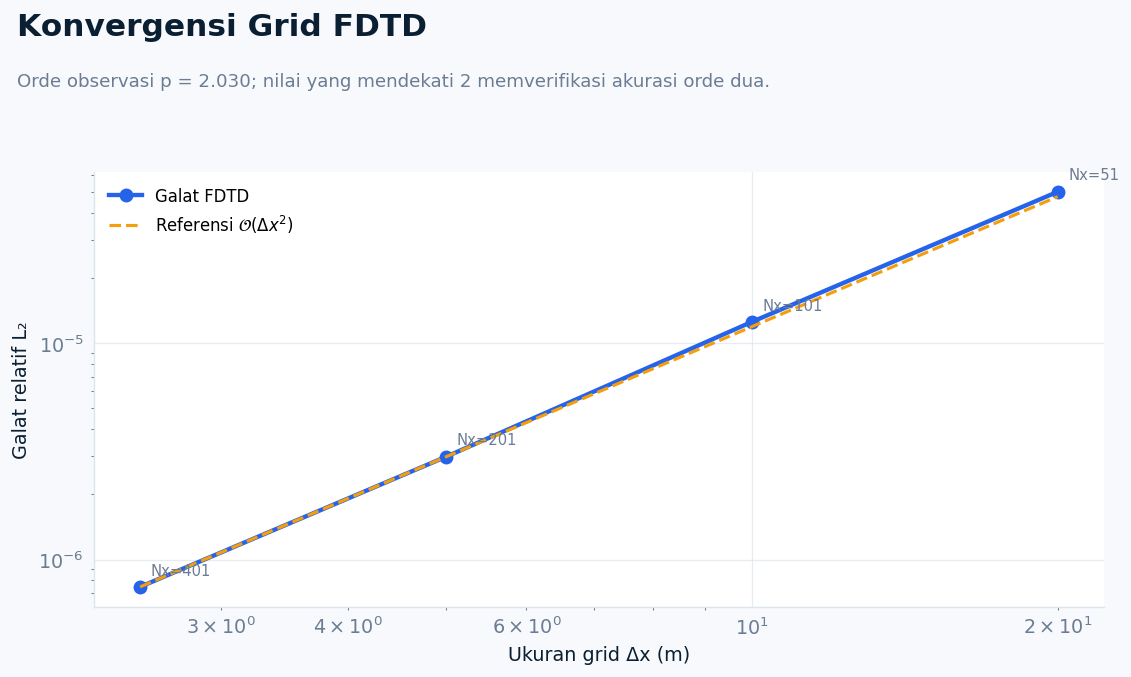

In [13]:
convergence_rows = []
for nx_test in [51, 101, 201, 401]:
    test = simulate_transmission_line(
        length=LENGTH,
        nx=nx_test,
        t_end=validation_time,
        courant=0.80,
        resistance=0.0,
        inductance=L_PER_M,
        conductance=0.0,
        capacitance=C_PER_M,
        initial_voltage=lambda x: np.sin(k_mode * x),
        initial_current=lambda x_half: np.zeros_like(x_half),
    )
    exact = np.sin(k_mode * test["x"]) * np.cos(c_wave * k_mode * test["t"][-1])
    error = np.sqrt(
        trapz((test["V"][-1] - exact) ** 2, test["x"])
        / trapz(exact**2, test["x"])
    )
    convergence_rows.append({
        "Nx": nx_test,
        "Δx (m)": test["dx"],
        "Δt (ns)": test["dt"] * 1e9,
        "Galat L2": error,
    })

convergence_df = pd.DataFrame(convergence_rows)
convergence_order = np.polyfit(
    np.log(convergence_df["Δx (m)"]),
    np.log(convergence_df["Galat L2"]),
    1
)[0]

display(polish_table(
    convergence_df,
    {"Δx (m)": "{:.4f}", "Δt (ns)": "{:.4f}", "Galat L2": "{:.3e}"},
    hide_index=True,
))

sorted_conv = convergence_df.sort_values("Δx (m)")
reference = (
    sorted_conv["Galat L2"].iloc[0]
    * (sorted_conv["Δx (m)"] / sorted_conv["Δx (m)"].iloc[0]) ** 2
)

fig, ax = plt.subplots(figsize=(9.5, 5.7), facecolor=BRAND["paper"])
ax.loglog(sorted_conv["Δx (m)"], sorted_conv["Galat L2"],
          marker="o", markersize=7, linewidth=2.5,
          color=BRAND["blue"], label="Galat FDTD")
ax.loglog(sorted_conv["Δx (m)"], reference,
          linestyle="--", linewidth=1.8, color=BRAND["amber"],
          label=r"Referensi $\mathcal{O}(\Delta x^2)$")
for _, row in sorted_conv.iterrows():
    ax.annotate(f"Nx={int(row['Nx'])}",
                (row["Δx (m)"], row["Galat L2"]),
                xytext=(6, 7), textcoords="offset points",
                fontsize=8.5, color=BRAND["muted"])
ax.set_xlabel("Ukuran grid Δx (m)")
ax.set_ylabel("Galat relatif L₂")
ax.legend()
style_axis(ax, "both")
figure_header(
    fig,
    "Konvergensi Grid FDTD",
    f"Orde observasi p = {convergence_order:.3f}; nilai yang mendekati 2 memverifikasi akurasi orde dua.",
)
fig.subplots_adjust(top=0.76, left=0.12, right=0.97, bottom=0.15)
plt.show()

# 9. Studi Parameter Fisik

## 9.1 Kondisi ideal, Heaviside, dan saluran tidak seimbang

Agar pengaruh distorsi tidak tertukar dengan redaman, saya membandingkan tiga kasus:

1. **ideal:** $R'=G'=0$;
2. **Heaviside:** $\beta=0$ dengan nilai $\alpha$ sama seperti kasus utama;
3. **tidak seimbang:** parameter utama dengan $\beta\ne0$.

Simulasi dihentikan sebelum pulsa menyentuh batas, sehingga perbedaan bentuk berasal dari parameter saluran, bukan refleksi.

Kasus,R′ (Ω/m),G′ (S/m),α (s⁻¹),β (s⁻¹),Peak akhir (V),Shape RMSE
Ideal,0.00000,0.000e+00,0.0,0.0,0.50000,0.00000
Heaviside (β=0),0.01125,4.500e-06,45000.0,0.0,0.46736,0.00001
Tidak seimbang,0.02000,1.000e-06,45000.0,35000.0,0.47183,0.01313


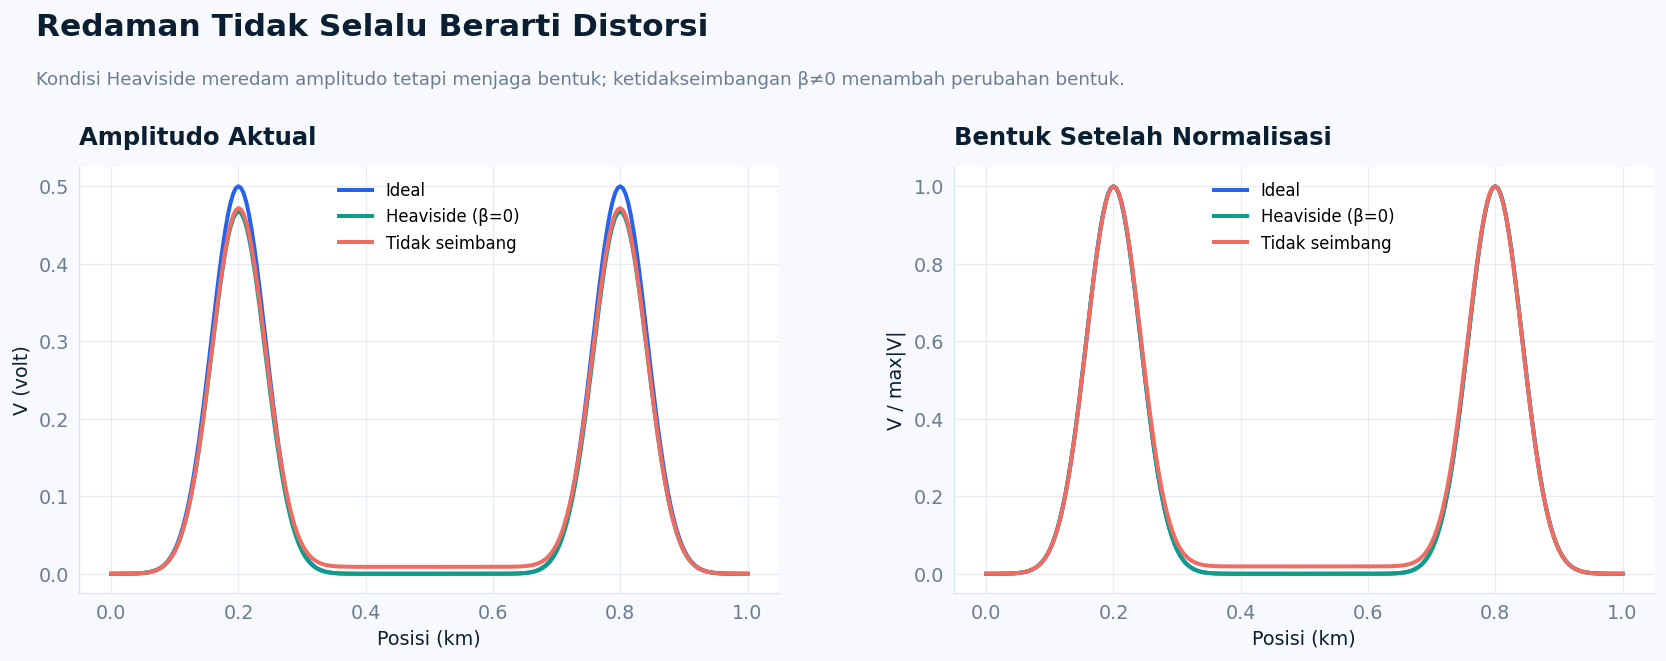

In [14]:
comparison_time = 1.5e-6
balanced_r = alpha * L_PER_M
balanced_g = alpha * C_PER_M
scenarios = [
    ("Ideal", 0.0, 0.0, BRAND["blue"]),
    ("Heaviside (β=0)", balanced_r, balanced_g, BRAND["teal"]),
    ("Tidak seimbang", R_PER_M, G_PER_M, BRAND["coral"]),
]

scenario_results = {}
scenario_rows = []
for name, r_value, g_value, color in scenarios:
    scenario = simulate_transmission_line(
        length=LENGTH,
        nx=NX,
        t_end=comparison_time,
        courant=COURANT_TARGET,
        resistance=r_value,
        inductance=L_PER_M,
        conductance=g_value,
        capacitance=C_PER_M,
        initial_voltage=initial_voltage,
        initial_current=initial_current,
    )
    scenario_results[name] = scenario
    alpha_case = 0.5 * (r_value / L_PER_M + g_value / C_PER_M)
    beta_case = 0.5 * (r_value / L_PER_M - g_value / C_PER_M)
    scenario_rows.append({
        "Kasus": name,
        "R′ (Ω/m)": r_value,
        "G′ (S/m)": g_value,
        "α (s⁻¹)": alpha_case,
        "β (s⁻¹)": beta_case,
        "Peak akhir (V)": np.max(np.abs(scenario["V"][-1])),
    })

ideal_final = scenario_results["Ideal"]["V"][-1]
ideal_normalized = ideal_final / np.max(np.abs(ideal_final))
for row in scenario_rows:
    final_profile = scenario_results[row["Kasus"]]["V"][-1]
    normalized = final_profile / np.max(np.abs(final_profile))
    row["Shape RMSE"] = np.sqrt(np.mean((normalized - ideal_normalized) ** 2))

scenario_df = pd.DataFrame(scenario_rows)
display(polish_table(
    scenario_df,
    {
        "R′ (Ω/m)": "{:.5f}", "G′ (S/m)": "{:.3e}",
        "α (s⁻¹)": "{:.1f}", "β (s⁻¹)": "{:.1f}",
        "Peak akhir (V)": "{:.5f}", "Shape RMSE": "{:.5f}",
    },
    hide_index=True,
))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), facecolor=BRAND["paper"])
for name, _, _, color in scenarios:
    profile = scenario_results[name]["V"][-1]
    axes[0].plot(result["x"] / 1e3, profile,
                 color=color, linewidth=2.3, label=name)
    axes[1].plot(result["x"] / 1e3, profile / np.max(np.abs(profile)),
                 color=color, linewidth=2.3, label=name)

axes[0].set_title("Amplitudo Aktual", loc="left")
axes[0].set_xlabel("Posisi (km)")
axes[0].set_ylabel("V (volt)")
axes[0].legend()
style_axis(axes[0], "both")

axes[1].set_title("Bentuk Setelah Normalisasi", loc="left")
axes[1].set_xlabel("Posisi (km)")
axes[1].set_ylabel("V / max|V|")
axes[1].legend()
style_axis(axes[1], "both")

figure_header(
    fig,
    "Redaman Tidak Selalu Berarti Distorsi",
    "Kondisi Heaviside meredam amplitudo tetapi menjaga bentuk; ketidakseimbangan β≠0 menambah perubahan bentuk.",
)
fig.subplots_adjust(top=0.76, left=0.08, right=0.98, bottom=0.14, wspace=0.25)
plt.show()

## 9.2 Sensitivitas terhadap resistansi seri

Saya menaikkan $R'$ sementara $G'$, $L'$, dan $C'$ dipertahankan. Eksperimen ini mengisolasi dampak rugi konduktor terhadap amplitudo dan energi.

R′ (Ω/m),α (s⁻¹),Energi tersisa,Peak |V| akhir
0.000,5000.0,92.39%,0.4809
0.010,25000.0,66.60%,0.4075
0.020,45000.0,48.08%,0.3450
0.040,85000.0,25.17%,0.2465
0.060,125000.0,13.30%,0.1753


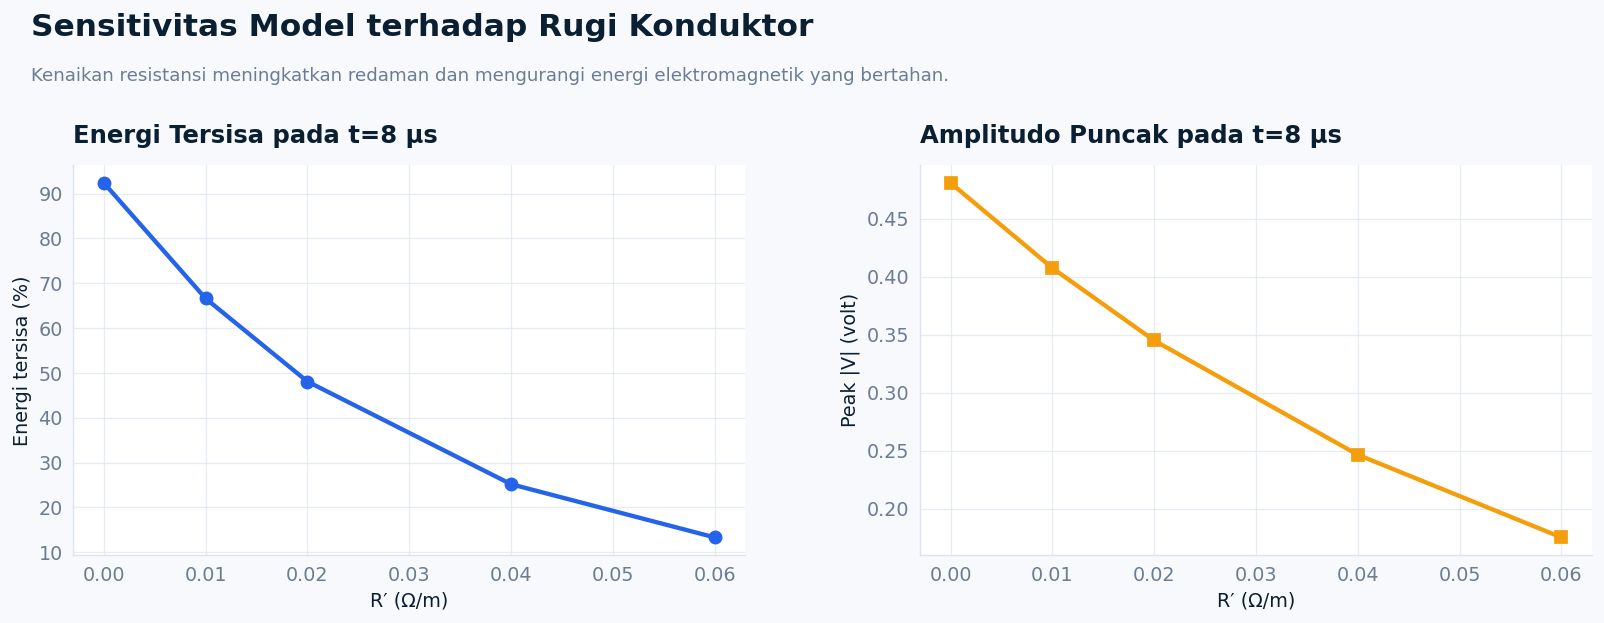

In [15]:
resistance_values = [0.0, 0.01, 0.02, 0.04, 0.06]
sweep_rows = []
for resistance_value in resistance_values:
    sweep = simulate_transmission_line(
        length=LENGTH,
        nx=161,
        t_end=8e-6,
        courant=COURANT_TARGET,
        resistance=resistance_value,
        inductance=L_PER_M,
        conductance=G_PER_M,
        capacitance=C_PER_M,
        initial_voltage=initial_voltage,
        initial_current=initial_current,
    )
    sweep_rows.append({
        "R′ (Ω/m)": resistance_value,
        "α (s⁻¹)": 0.5 * (
            resistance_value / L_PER_M + G_PER_M / C_PER_M
        ),
        "Energi tersisa": sweep["energy"][-1] / sweep["energy"][0],
        "Peak |V| akhir": np.max(np.abs(sweep["V"][-1])),
    })

sweep_df = pd.DataFrame(sweep_rows)
display(polish_table(
    sweep_df,
    {
        "R′ (Ω/m)": "{:.3f}", "α (s⁻¹)": "{:.1f}",
        "Energi tersisa": "{:.2%}", "Peak |V| akhir": "{:.4f}",
    },
    hide_index=True,
))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), facecolor=BRAND["paper"])
axes[0].plot(sweep_df["R′ (Ω/m)"], sweep_df["Energi tersisa"] * 100,
             color=BRAND["blue"], marker="o", markersize=7, linewidth=2.5)
axes[0].set_title("Energi Tersisa pada t=8 μs", loc="left")
axes[0].set_xlabel("R′ (Ω/m)")
axes[0].set_ylabel("Energi tersisa (%)")
style_axis(axes[0], "both")

axes[1].plot(sweep_df["R′ (Ω/m)"], sweep_df["Peak |V| akhir"],
             color=BRAND["amber"], marker="s", markersize=6.5, linewidth=2.5)
axes[1].set_title("Amplitudo Puncak pada t=8 μs", loc="left")
axes[1].set_xlabel("R′ (Ω/m)")
axes[1].set_ylabel("Peak |V| (volt)")
style_axis(axes[1], "both")

figure_header(
    fig,
    "Sensitivitas Model terhadap Rugi Konduktor",
    "Kenaikan resistansi meningkatkan redaman dan mengurangi energi elektromagnetik yang bertahan.",
)
fig.subplots_adjust(top=0.75, left=0.08, right=0.98, bottom=0.15, wspace=0.26)
plt.show()

# 10. Dashboard Verifikasi Numerik

Sebelum menarik kesimpulan, saya merangkum empat pemeriksaan utama:

- stabilitas CFL;
- konsistensi neraca energi;
- orde konvergensi;
- pemenuhan kondisi batas.

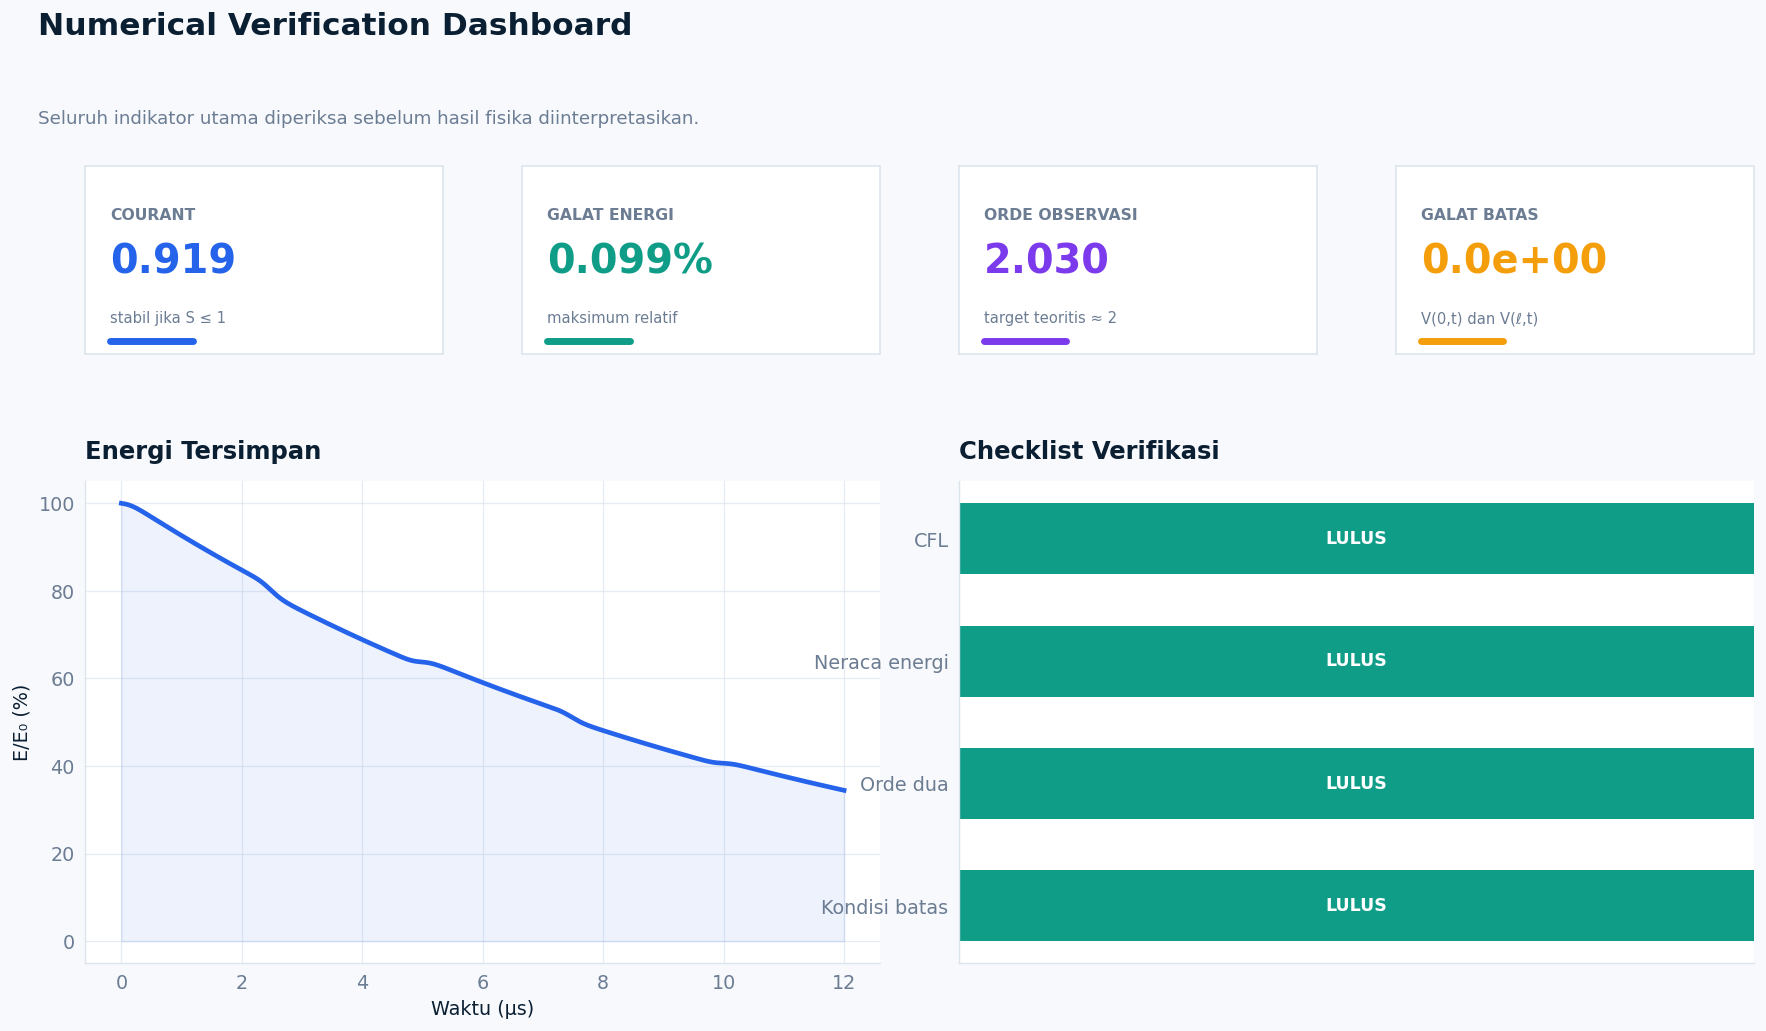

Pemeriksaan,Status
CFL,LULUS
Neraca energi,LULUS
Orde dua,LULUS
Kondisi batas,LULUS


In [16]:
boundary_error = max(
    np.max(np.abs(result["V"][:, 0])),
    np.max(np.abs(result["V"][:, -1]))
)
energy_fraction = result["energy"][-1] / result["energy"][0]
stable_status = result["courant"] <= 1.0
convergent_status = 1.8 <= convergence_order <= 2.2

fig = plt.figure(figsize=(15, 8.5), facecolor=BRAND["paper"])
gs = fig.add_gridspec(2, 4, height_ratios=[0.78, 2.0], hspace=0.38, wspace=0.22)

dashboard_cards = [
    ("Courant", f"{result['courant']:.3f}",
     "stabil jika S ≤ 1", BRAND["blue"]),
    ("Galat energi", f"{relative_balance_error:.3%}",
     "maksimum relatif", BRAND["teal"]),
    ("Orde observasi", f"{convergence_order:.3f}",
     "target teoritis ≈ 2", BRAND["purple"]),
    ("Galat batas", f"{boundary_error:.1e}",
     "V(0,t) dan V(ℓ,t)", BRAND["amber"]),
]
for idx, card in enumerate(dashboard_cards):
    metric_card(fig.add_subplot(gs[0, idx]), *card)

ax_left = fig.add_subplot(gs[1, :2])
ax_left.plot(time_us, 100 * result["energy"] / result["energy"][0],
             color=BRAND["blue"], linewidth=2.7)
ax_left.fill_between(
    time_us, 100 * result["energy"] / result["energy"][0], 0,
    color=BRAND["blue"], alpha=0.08
)
ax_left.set_title("Energi Tersimpan", loc="left")
ax_left.set_xlabel("Waktu (μs)")
ax_left.set_ylabel("E/E₀ (%)")
style_axis(ax_left, "both")

ax_right = fig.add_subplot(gs[1, 2:])
checks = ["CFL", "Neraca energi", "Orde dua", "Kondisi batas"]
passed = [
    stable_status,
    relative_balance_error < 0.01,
    convergent_status,
    boundary_error < 1e-12,
]
check_colors = [BRAND["teal"] if item else BRAND["coral"] for item in passed]
bars = ax_right.barh(checks, [1, 1, 1, 1],
                     color=check_colors, height=0.58)
ax_right.invert_yaxis()
for y, status in enumerate(passed):
    ax_right.text(0.5, y, "LULUS" if status else "TINJAU",
                  ha="center", va="center", color="white",
                  fontweight="bold", fontsize=10)
ax_right.set_xlim(0, 1)
ax_right.set_xticks([])
ax_right.set_title("Checklist Verifikasi", loc="left")
style_axis(ax_right, grid=None)

figure_header(
    fig,
    "Numerical Verification Dashboard",
    "Seluruh indikator utama diperiksa sebelum hasil fisika diinterpretasikan.",
)
fig.subplots_adjust(top=0.84, left=0.08, right=0.97, bottom=0.09)
plt.show()

verification_df = pd.DataFrame({
    "Pemeriksaan": checks,
    "Status": ["LULUS" if item else "TINJAU" for item in passed],
})
display(polish_table(verification_df, hide_index=True))

# 11. Keterbatasan dan Pengembangan

## 11.1 Keterbatasan model saya

1. **Satu dimensi.** Model tidak menyelesaikan distribusi medan transversal $\mathbf E$ dan $\mathbf H$.
2. **Linear dan homogen.** $R',L',G',C'$ tidak berubah terhadap posisi, waktu, suhu, atau amplitudo.
3. **Terminasi ideal.** Ujung hubung-singkat adalah skenario terkontrol; beban nyata memiliki impedansi kompleks.
4. **Tidak bergantung frekuensi.** Skin effect dan rugi dielektrik dispersif belum dimodelkan.
5. **Sumber hanya kondisi awal.** Notebook belum memakai generator dengan impedansi internal.
6. **FDTD eksplisit.** Langkah waktu dibatasi CFL; grid sangat halus meningkatkan biaya komputasi.

## 11.2 Pengembangan yang saya rekomendasikan

- menambahkan batas beban $Z_L$ dan menghitung koefisien refleksi $\Gamma=(Z_L-Z_0)/(Z_L+Z_0)$;
- memakai sumber sinus, pulsa digital, atau modulasi untuk studi integritas sinyal;
- membuat $R'$ dan $G'$ bergantung frekuensi;
- memperluas ke FDTD Maxwell 2D/3D atau metode elemen hingga;
- membandingkan hasil dengan SPICE atau pengukuran laboratorium;
- menerapkan Perfectly Matched Layer untuk batas serap nonreflektif.

# 12. Kesimpulan dan Refleksi Akhir

Melalui notebook ini saya menunjukkan bahwa Persamaan Telegraf bukan hanya persamaan gelombang abstrak. Setiap sukunya terhubung langsung dengan penyimpanan energi, rugi konduktor, kebocoran dielektrik, dan aliran daya pada saluran transmisi.

Temuan utama saya:

1. skema FDTD staggered-grid mereproduksi pemisahan pulsa, perambatan, redaman, dan refleksi secara stabil;
2. bilangan Courant di bawah satu mencegah pertumbuhan solusi yang tidak fisik;
3. energi elektromagnetik yang hilang konsisten dengan integral daya rugi $R'I^2+G'V^2$;
4. solusi numerik berimpit dengan solusi analitik mode tunggal;
5. studi grid menunjukkan konvergensi mendekati orde dua;
6. kondisi Heaviside membedakan redaman amplitudo dari distorsi bentuk gelombang;
7. animasi memperjelas hubungan tanda arus, arah rambat, refleksi, dan disipasi energi.

Dengan demikian, simulasi ini telah memenuhi tiga lapis verifikasi: **matematis**, **numerik**, dan **fisik**.

In [17]:
display(Markdown(
    "### Ringkasan hasil yang dapat direproduksi\n\n"
    f"- Kecepatan rambat: **{c_wave:.3e} m/s**.\n"
    f"- Impedansi karakteristik: **{z0:.2f} Ω**.\n"
    f"- Courant aktual: **{result['courant']:.4f}**.\n"
    f"- Energi tersisa pada akhir simulasi: **{energy_fraction:.2%}**.\n"
    f"- Galat maksimum neraca energi: **{relative_balance_error:.4%}**.\n"
    f"- Galat validasi tegangan L₂: **{v_l2_error:.3e}**.\n"
    f"- Galat validasi arus L₂: **{i_l2_error:.3e}**.\n"
    f"- Orde konvergensi observasi: **{convergence_order:.3f}**.\n"
    f"- Status pemeriksaan utama: **{sum(passed)}/{len(passed)} LULUS**."
))

### Ringkasan hasil yang dapat direproduksi

- Kecepatan rambat: **2.000e+08 m/s**.
- Impedansi karakteristik: **50.00 Ω**.
- Courant aktual: **0.9187**.
- Energi tersisa pada akhir simulasi: **34.46%**.
- Galat maksimum neraca energi: **0.0993%**.
- Galat validasi tegangan L₂: **2.019e-06**.
- Galat validasi arus L₂: **1.573e-05**.
- Orde konvergensi observasi: **2.030**.
- Status pemeriksaan utama: **4/4 LULUS**.

# Referensi

1. D. M. Pozar, *Microwave Engineering*, 4th ed., Wiley, 2012.
2. S. Ramo, J. R. Whinnery, & T. Van Duzer, *Fields and Waves in Communication Electronics*, 3rd ed., Wiley, 1994.
3. A. Taflove & S. C. Hagness, *Computational Electrodynamics: The Finite-Difference Time-Domain Method*, 3rd ed., Artech House, 2005.
4. J. C. Strikwerda, *Finite Difference Schemes and Partial Differential Equations*, 2nd ed., SIAM, 2004.
5. R. F. Harrington, *Time-Harmonic Electromagnetic Fields*, Wiley-IEEE Press, 2001.
6. NumPy Developers, dokumentasi komputasi array dan integrasi trapezoid.
7. Matplotlib Developers, dokumentasi visualisasi dan <i>FuncAnimation</i>.

---

**Pernyataan reprodusibilitas:** seluruh parameter, kondisi awal, solver, validasi, grafik, dan animasi dihasilkan langsung oleh sel yang ditampilkan. Tidak ada hasil numerik yang diketik manual.